In [1]:
import numpy as np
import matplotlib.pyplot as plt
from numba import njit, prange
from tqdm import tqdm
from scipy.signal import correlate
from scipy.stats import multivariate_normal
import os
import sys

import matplotlib

import plotly.graph_objects as go

from scipy.ndimage import gaussian_filter

module_path = os.path.abspath(os.path.join('..'))
if module_path not in sys.path:
    sys.path.append(module_path)

from GLOBAL.ground_truths import *
from GLOBAL.torque import *
from GLOBAL.filters import *

max_angle = 1000000 * np.pi / 180

with np.load("../GLOBAL/data.npz") as data:
    x_data=data['x_data']
    y_data=data['y_data']

n_trajectories = 20
x_data = x_data[:n_trajectories, :]
y_data = y_data[:n_trajectories, :]

# Find proposal

In [2]:
def plot_torques(MEANS, COVS, n_knots=None, n_samples=10000, n_phis = 200, n_examples=0, torque_scale=50, plot_edges=True, use_Bsplines=False):

    TORQUE_FN = TORQUE_FILTER if use_Bsplines else TORQUE_FILTER
    #plt.figure(figsize=(4, 4))

    #MEANS = [m[1:] for m in MEANS]
    #COVS = [c[1:,1:] for c in COVS]
    
    phi = np.linspace(-np.pi * 0.1, 2.1 * np.pi, n_phis)
    phi_draw = phi * 180 / np.pi

    use = -1
    sample_mean = np.mean(MEANS[use:], axis=0)
    sample_cov = np.mean(np.array(COVS[use:]), axis=0)

    TORQUES = []

    SAMPLES = np.random.multivariate_normal(sample_mean, sample_cov, n_samples)


    for s in SAMPLES:
        TORQUES.append(TORQUE_FN(phi, s))

    TORQUES = np.array(TORQUES)

    Tmax = torque_scale
    Tmin = -torque_scale

    bins = np.linspace(Tmin, Tmax, n_phis)

    extent = [phi_draw.min(), phi_draw.max(), Tmin, Tmax]
    def hist1d(x):
        hist = np.histogram(x, bins=bins, density=True)[0]
        return hist / hist.max()

    density = np.apply_along_axis(hist1d, axis=0, arr=TORQUES, )

    density_ = gaussian_filter(density, (0.0,0))
    #plt.figure(dpi=300)
    cmap = matplotlib.colors.LinearSegmentedColormap.from_list("", ["white","cornflowerblue"])
    plt.imshow(density_, extent=extent, aspect='auto', origin='lower', cmap=cmap)

    torque_mean = np.mean(TORQUES, axis=0)
    torque_mode = bins[np.argmax(density_, axis=0)]
    torque_std = np.std(TORQUES, axis=0)

    torque_true = TORQUE(phi, ALPHAS)

    #if n_knots is not None:
    #    phi_knots = np.linspace(0, np.pi, n_knots+2)[1:-1]
    #    torque_knots = TORQUE(phi_knots, ALPHAS)
    #
    #    plt.scatter(phi_knots, torque_knots, c='r', s=10)
    #    #for phi_ in phi_knots:
    #    #    plt.axvline(phi_, color='k', alpha=0.5, lw=0.5, ls='--')

    
    for i in range(n_examples):

        SAMPLES = np.random.multivariate_normal(sample_mean, sample_cov, 1)

        TORQUES = []
        for s in SAMPLES:
            TORQUES.append(TORQUE_FN(phi, s))
        
        plt.plot(phi_draw, TORQUES[0], lw=1, alpha=1, ls='--', c='darkgreen')

    col='mediumblue'
    qtil = 2.575829
    
    plt.plot(phi_draw, torque_mean - qtil*torque_std, '-', lw=0.7, c=col)
    plt.plot(phi_draw, torque_mean + qtil*torque_std, '-', lw=0.7, c=col)
    #plt.plot(phi, torque_mode, '--', lw=0.7, alpha=1, c=col)
    #plt.plot(phi, torque_true, '-', lw=2, alpha=1, c='r')
    if plot_edges:
        plt.axvline(0, color='k', lw=2)
        plt.axvline(360, color='k', lw=2)
    plt.grid()
    plt.ylim(Tmin, Tmax)
    plt.xticks(np.arange(0, 360+1, 90))

    

    

In [3]:
def plot_cov_ellipse(mean, cov, color='b'):
    phi = np.linspace(0, 2*np.pi, 100)
    chol = np.linalg.cholesky(cov[:2, :2])
    ellipse = np.array([np.cos(phi), np.sin(phi)])
    plt.plot(*(chol@ellipse + mean[:2][:, None]), c=color)
    ellipse = 2*np.array([np.cos(phi), np.sin(phi)])
    plt.plot(*(chol@ellipse + mean[:2][:, None]), c=color, ls='--')

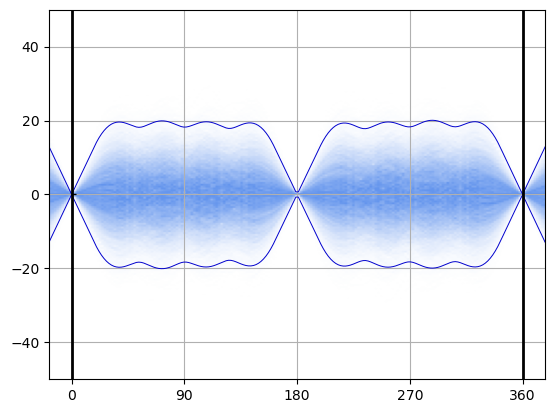

In [4]:
search_size = 1.5
initial_radius = 100


d0 = 0
d1 = 1
#centers = np.array([10] * ndims)
# = np.linspace(0, np.pi, ndims+2)
#centers = TORQUE(phi_torques, ALPHAS)[1:-1]
centers = np.array((-20, 10))
ndims = centers.shape[0]


ndims = 4
centers = np.zeros(ndims)

mean = centers.copy()
cov = np.eye(ndims) * initial_radius

cov_transform = np.zeros((ndims, ndims))
cov_transform[:, 0] = 1

# Make the initial guess a constant function (just for illustration, not useful)
#cov = cov_transform @ cov @ cov_transform.T

COVS = [cov.copy()]
MEANS = [mean.copy()]
ALL_COORDS = np.zeros((0, ndims))
ALL_TARGET_DENSITIES = np.zeros(0)
ALL_LIKELIHOODS = np.zeros(0)
count = 0

plot_torques(MEANS, COVS, n_knots=ndims)

phi_ = np.linspace(0, np.pi, 300)
torque_ = TORQUE_FILTER(phi_, mean)
plt.plot(phi_, torque_, 'k--', lw=1)

  0%|                                                                                           | 0/50 [00:00<?, ?it/s]

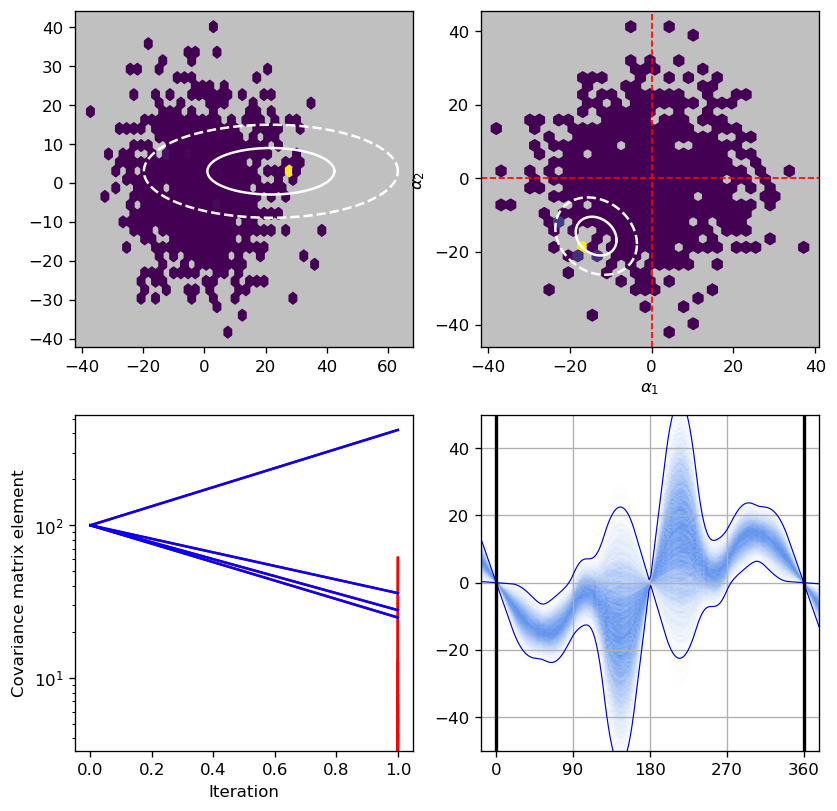

  2%|█▋                                                                                 | 1/50 [00:23<19:25, 23.78s/it]

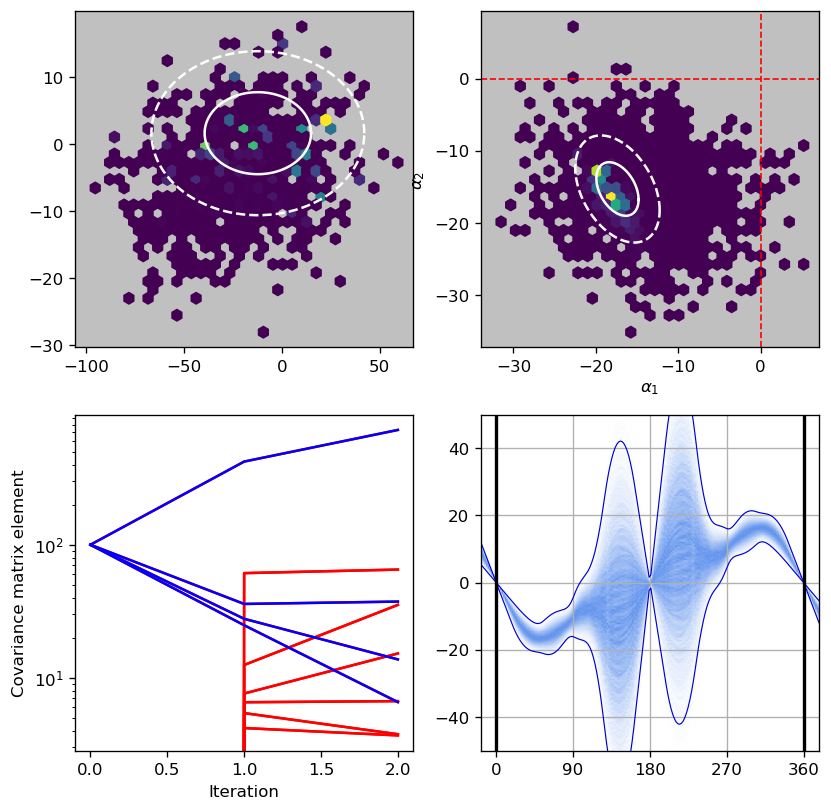

  4%|███▎                                                                               | 2/50 [00:44<17:30, 21.89s/it]

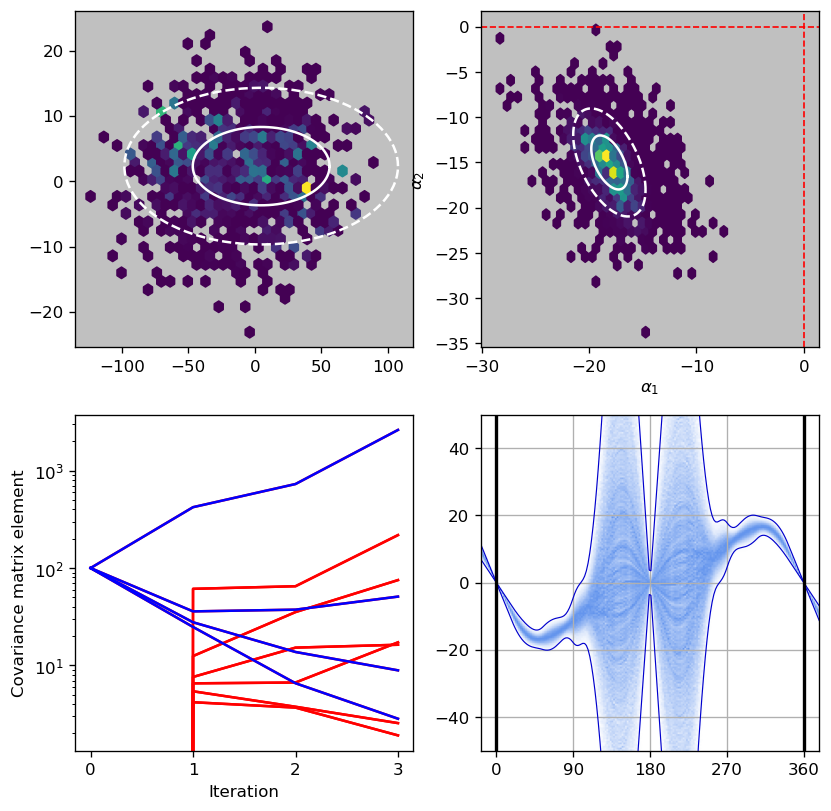

  6%|████▉                                                                              | 3/50 [01:05<16:43, 21.36s/it]

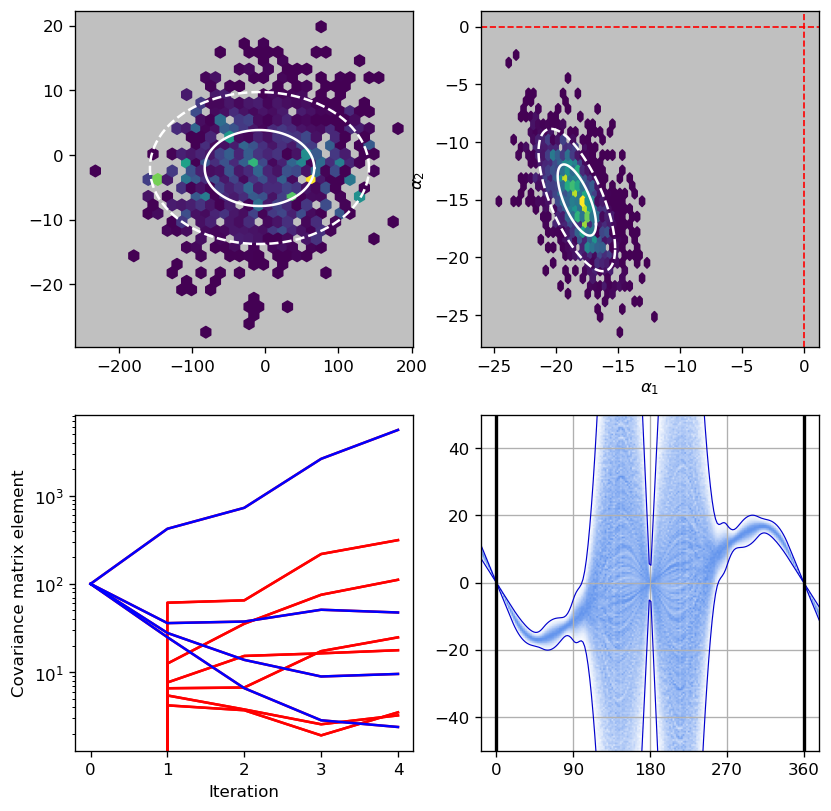

  8%|██████▋                                                                            | 4/50 [01:25<16:13, 21.15s/it]

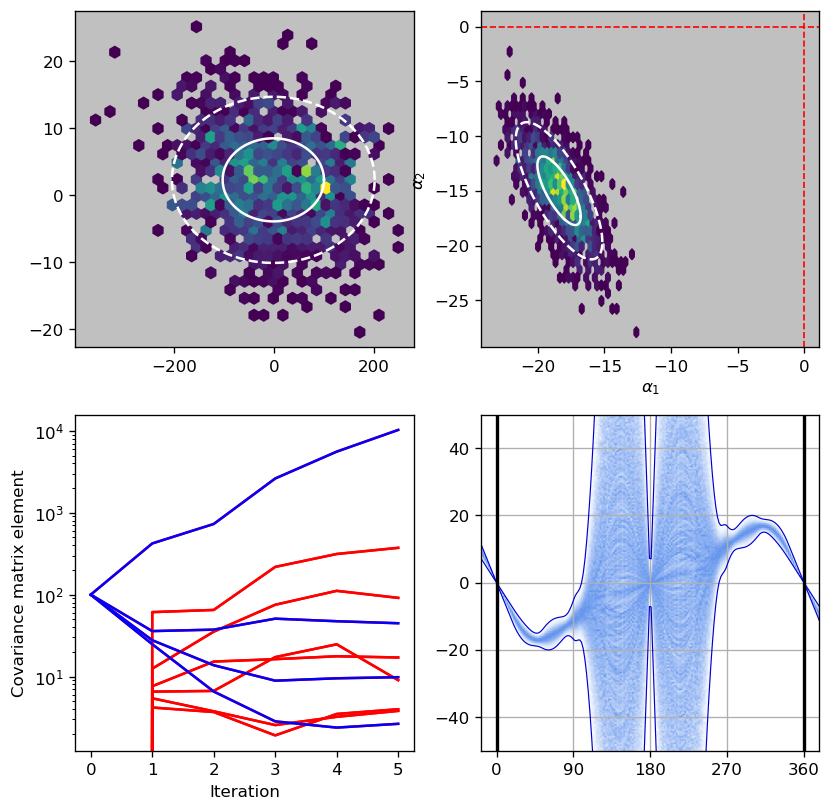

 10%|████████▎                                                                          | 5/50 [01:46<15:35, 20.79s/it]

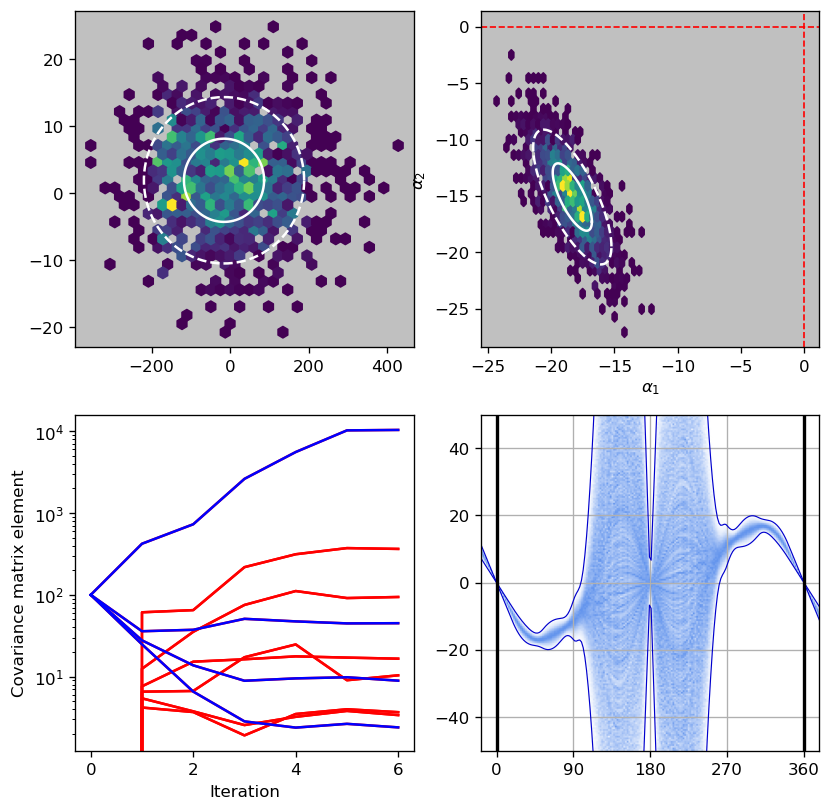

 12%|█████████▉                                                                         | 6/50 [02:05<14:54, 20.33s/it]

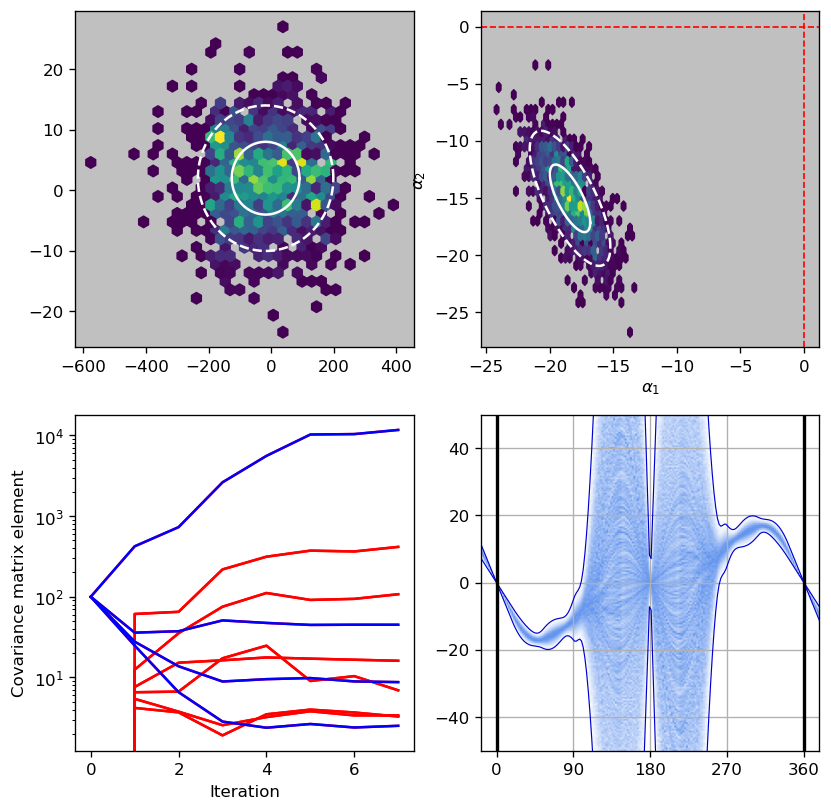

 14%|███████████▌                                                                       | 7/50 [02:24<14:09, 19.76s/it]

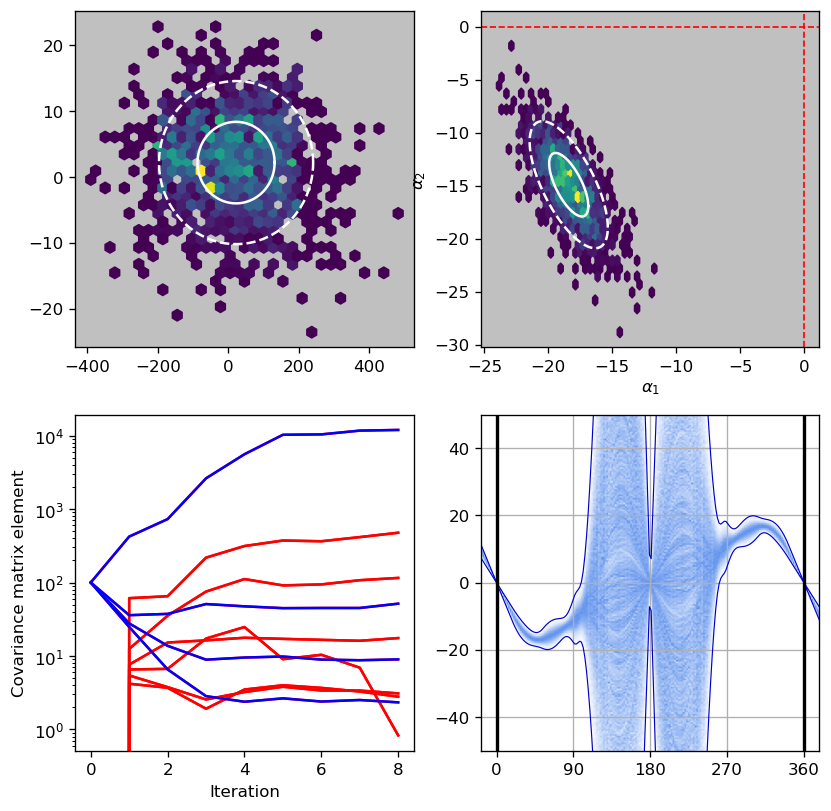

 16%|█████████████▎                                                                     | 8/50 [02:41<13:23, 19.13s/it]

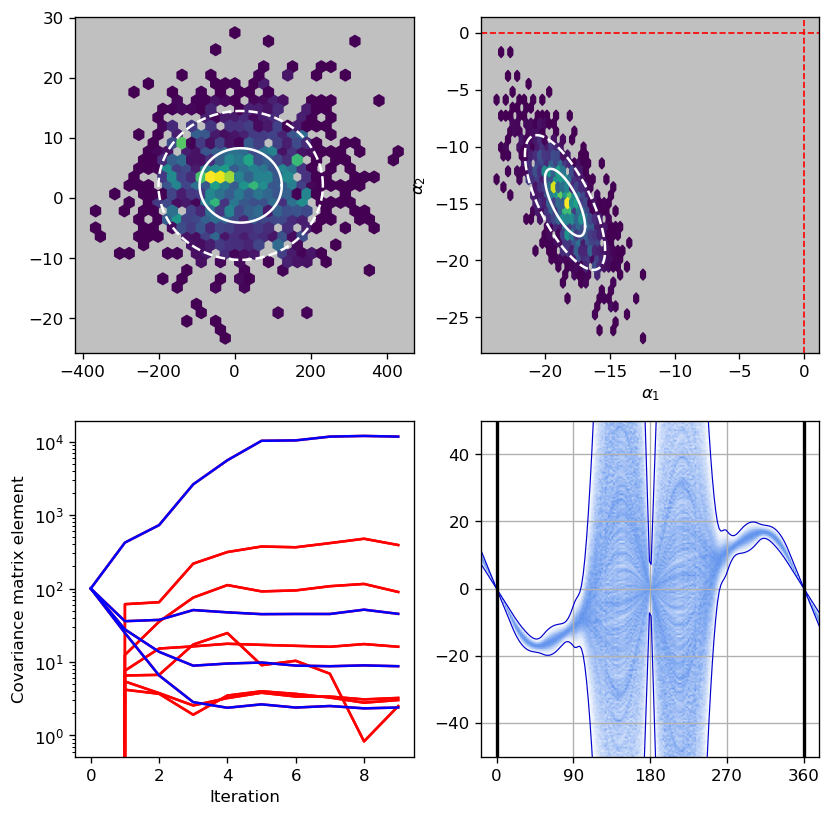

 18%|██████████████▉                                                                    | 9/50 [03:00<12:51, 18.83s/it]

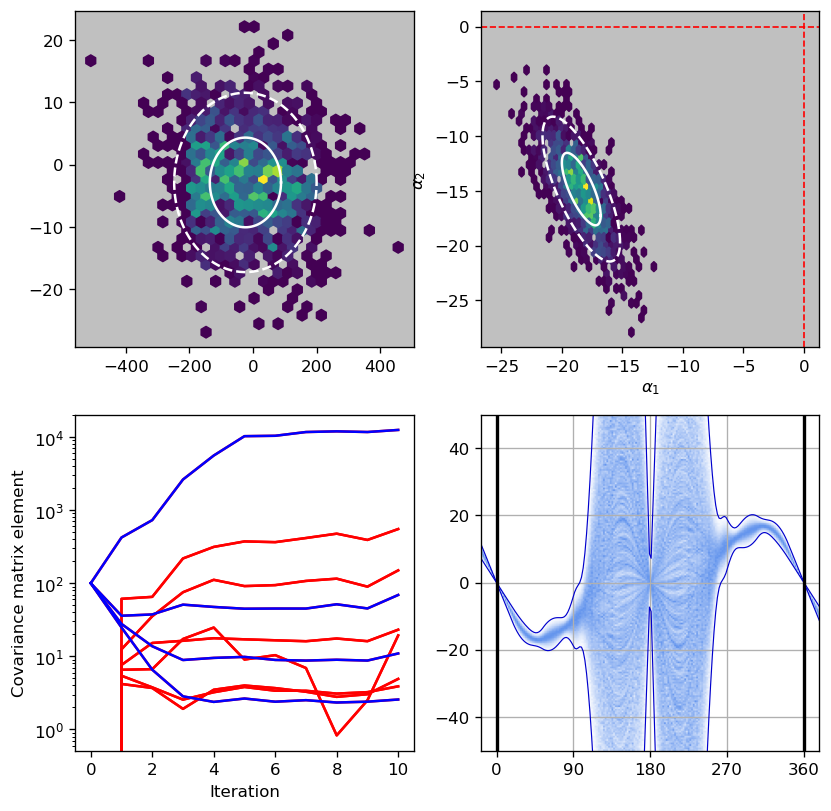

 20%|████████████████▍                                                                 | 10/50 [03:18<12:23, 18.59s/it]

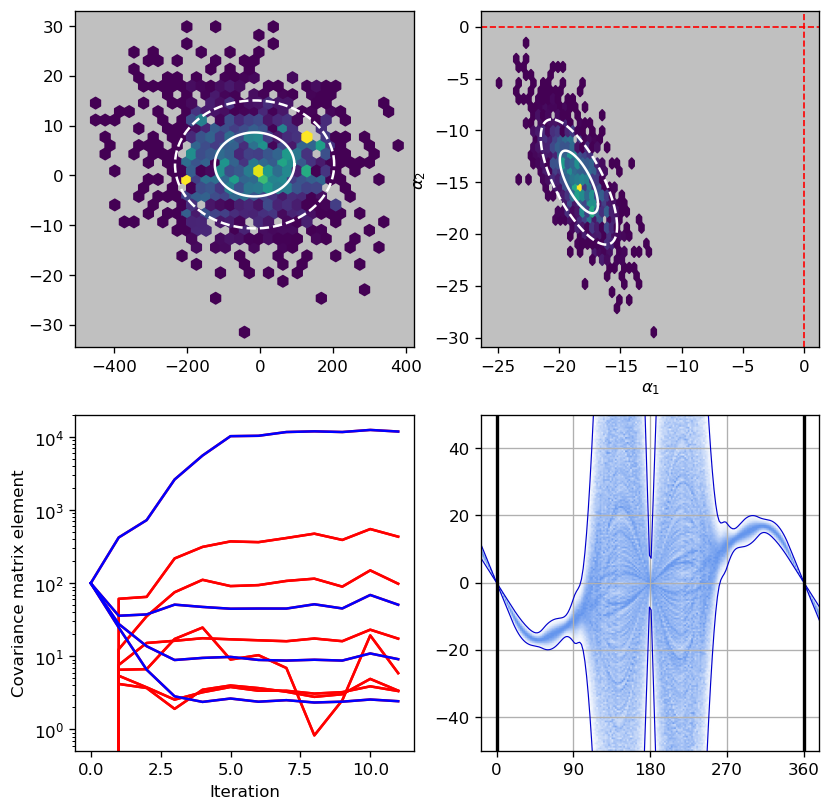

 22%|██████████████████                                                                | 11/50 [03:35<11:56, 18.36s/it]

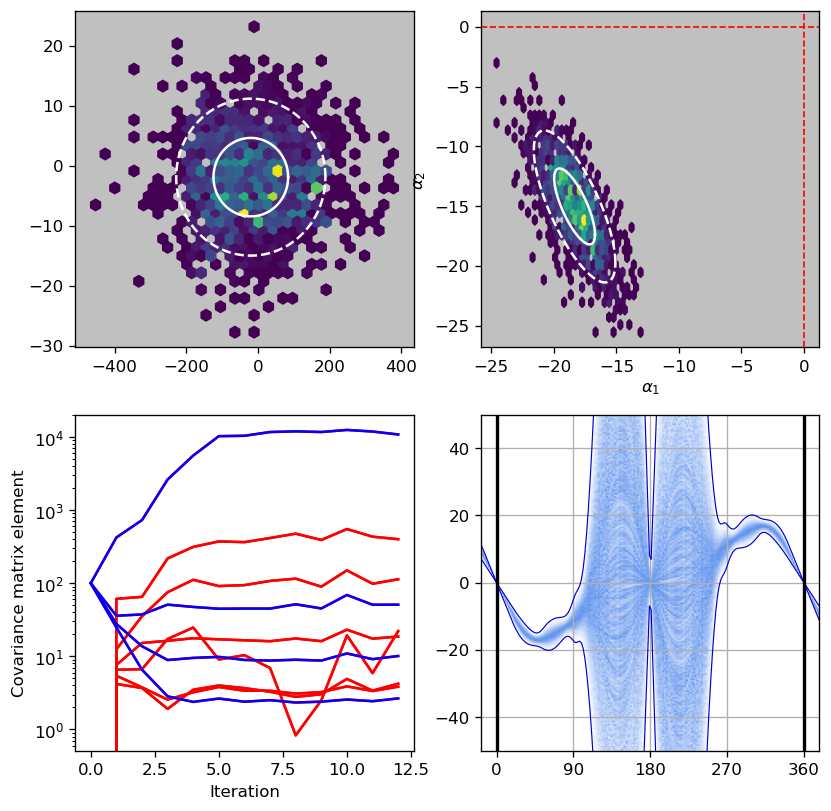

 24%|███████████████████▋                                                              | 12/50 [03:54<11:41, 18.46s/it]

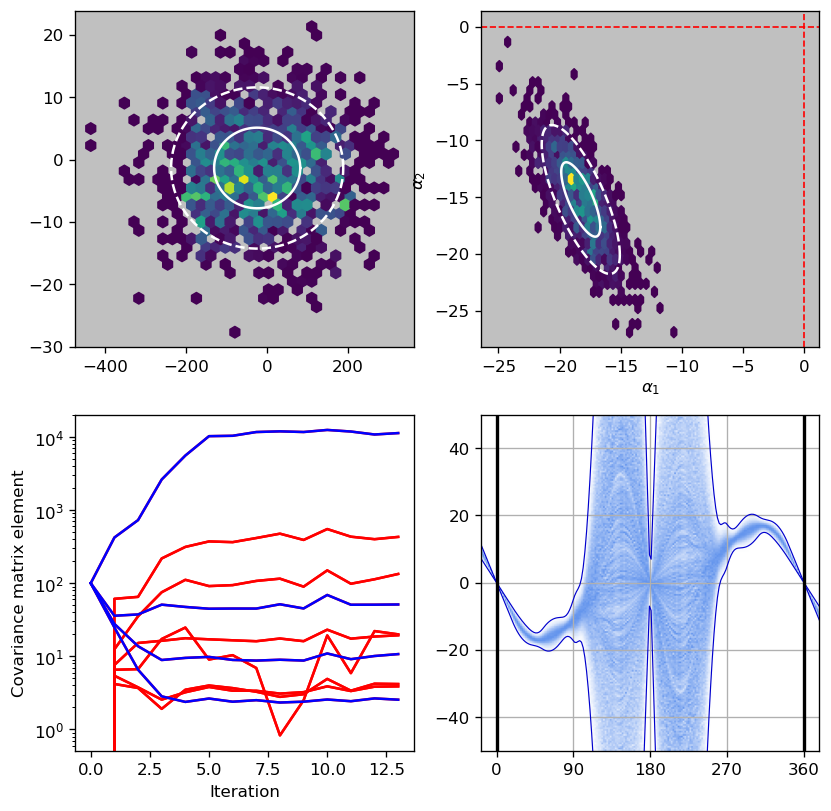

 26%|█████████████████████▎                                                            | 13/50 [04:13<11:24, 18.50s/it]

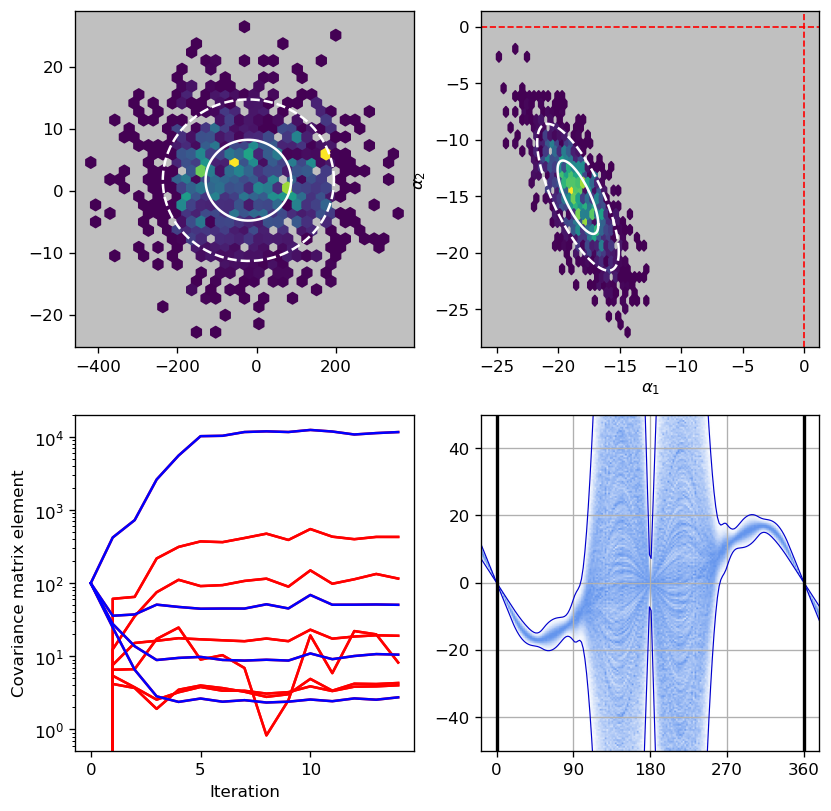

 28%|██████████████████████▉                                                           | 14/50 [04:31<11:00, 18.36s/it]

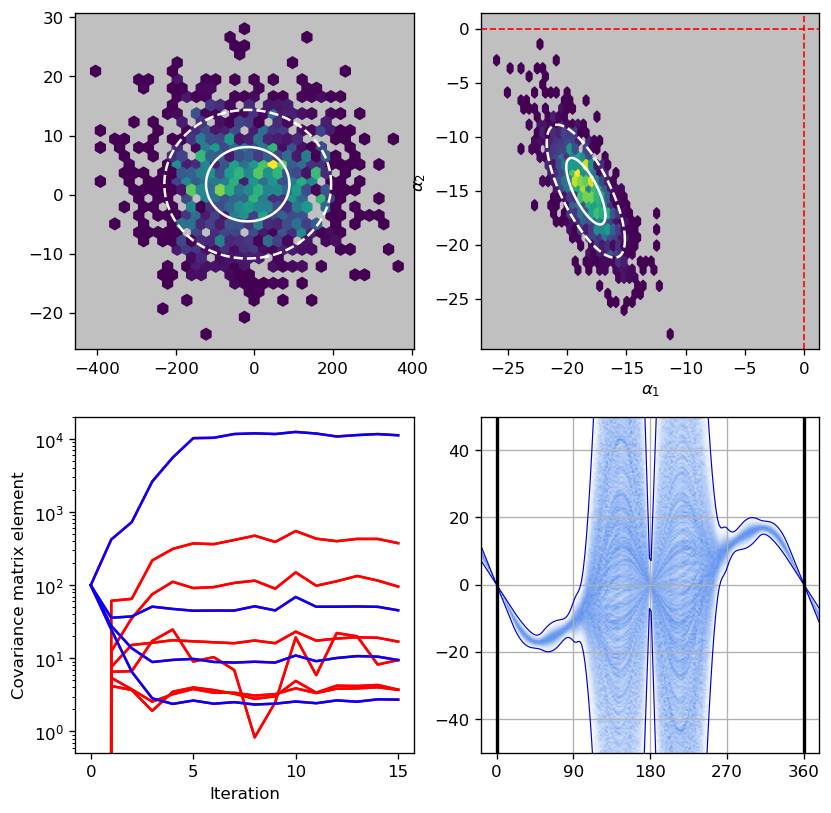

 30%|████████████████████████▌                                                         | 15/50 [04:49<10:37, 18.20s/it]

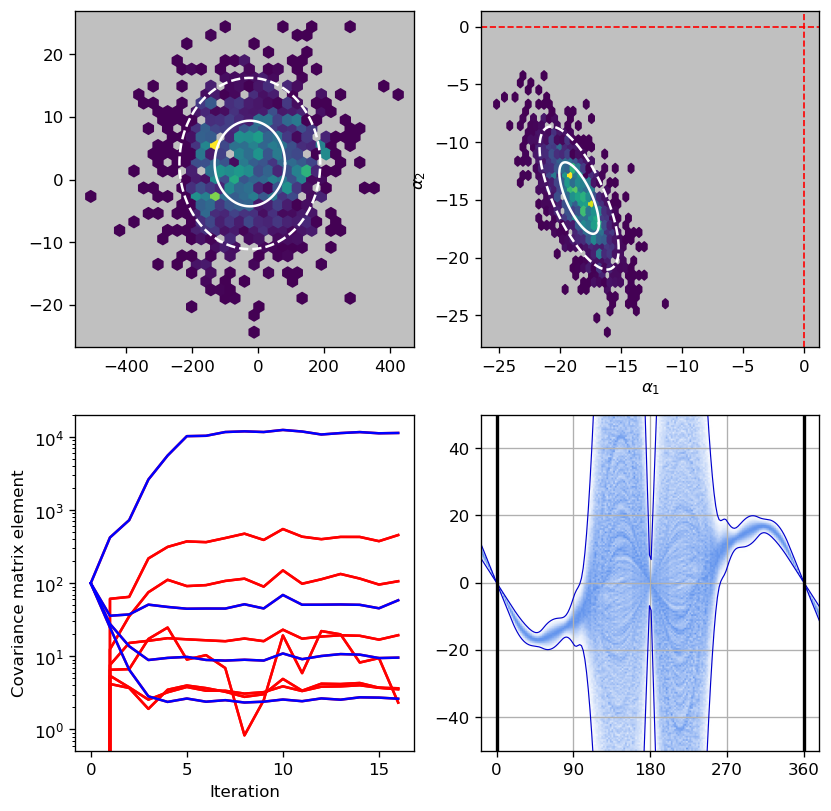

 32%|██████████████████████████▏                                                       | 16/50 [05:07<10:25, 18.41s/it]

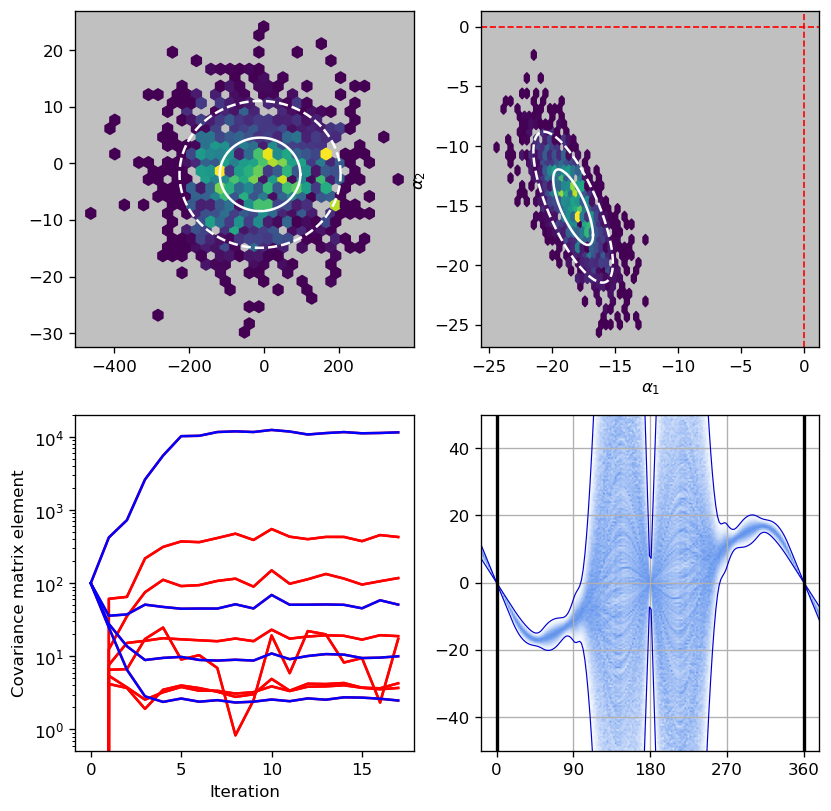

 34%|███████████████████████████▉                                                      | 17/50 [05:26<10:05, 18.34s/it]

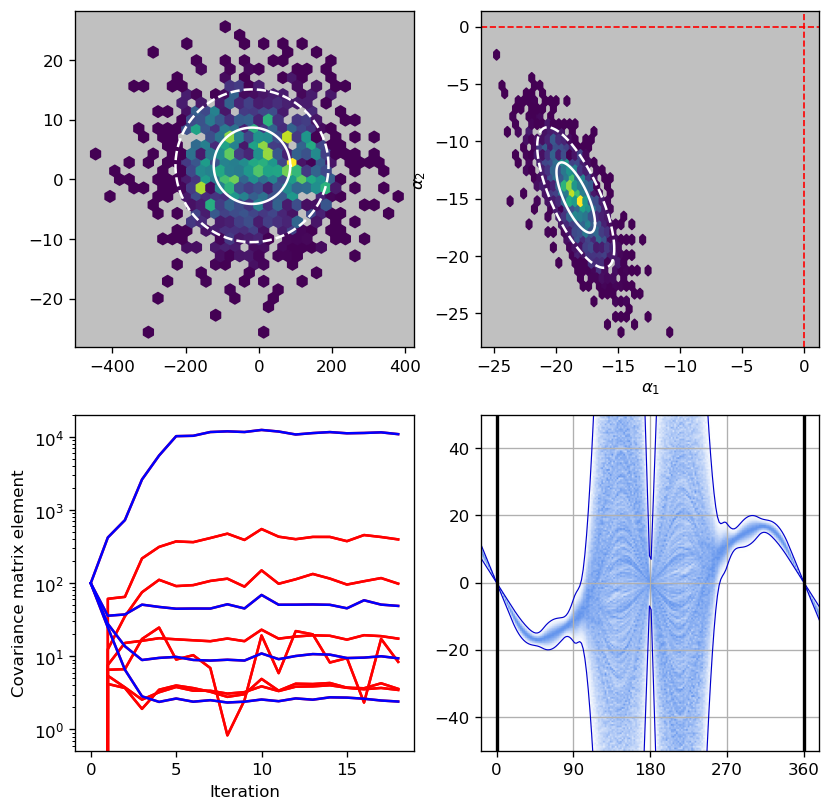

 36%|█████████████████████████████▌                                                    | 18/50 [05:44<09:44, 18.26s/it]

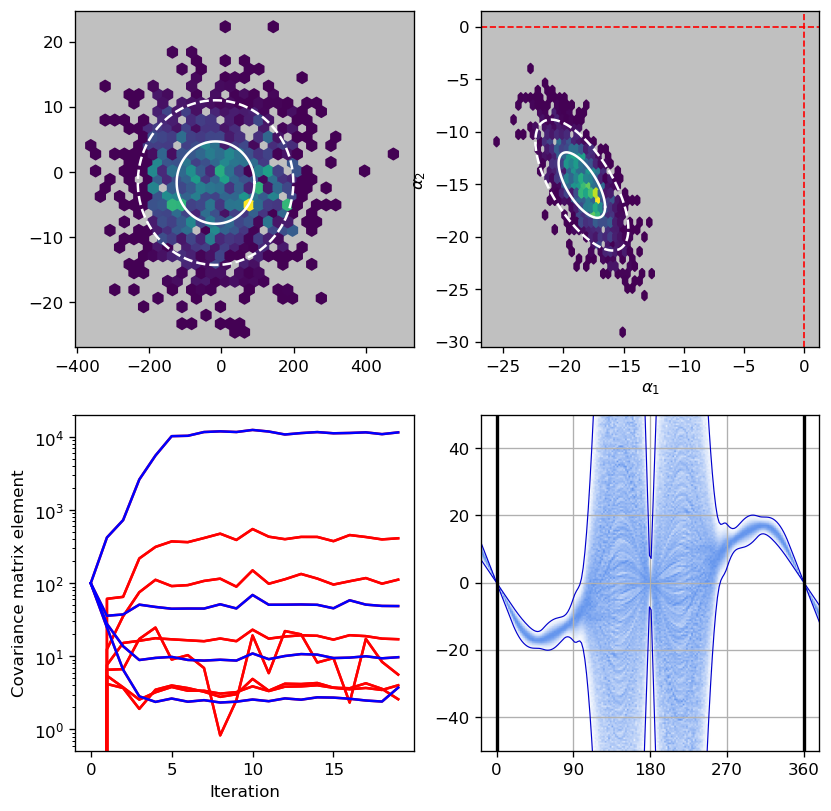

 38%|███████████████████████████████▏                                                  | 19/50 [06:02<09:25, 18.26s/it]

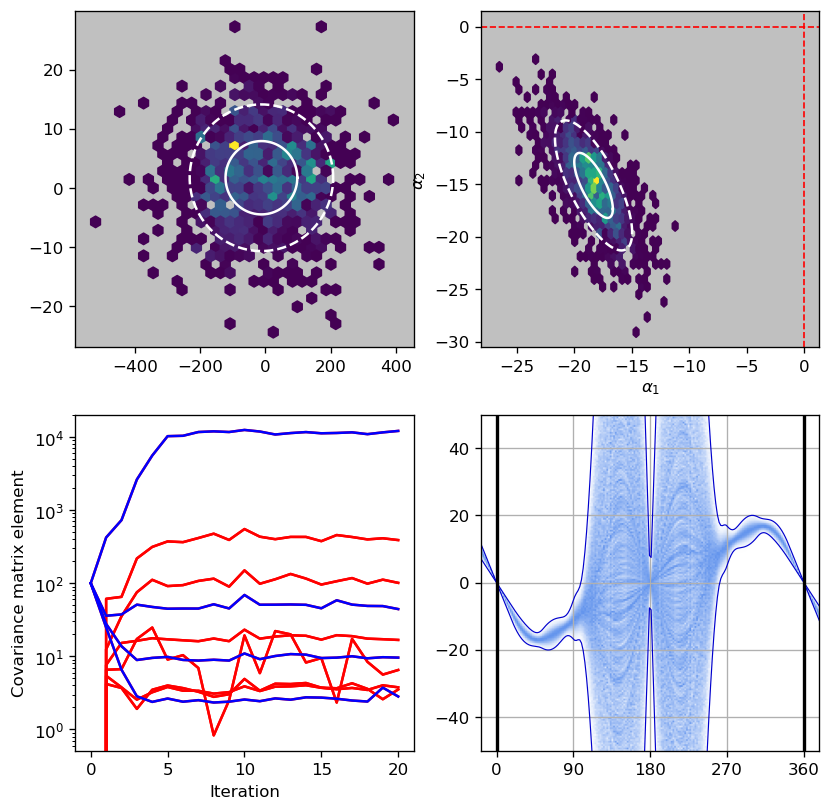

 40%|████████████████████████████████▊                                                 | 20/50 [06:20<09:04, 18.16s/it]

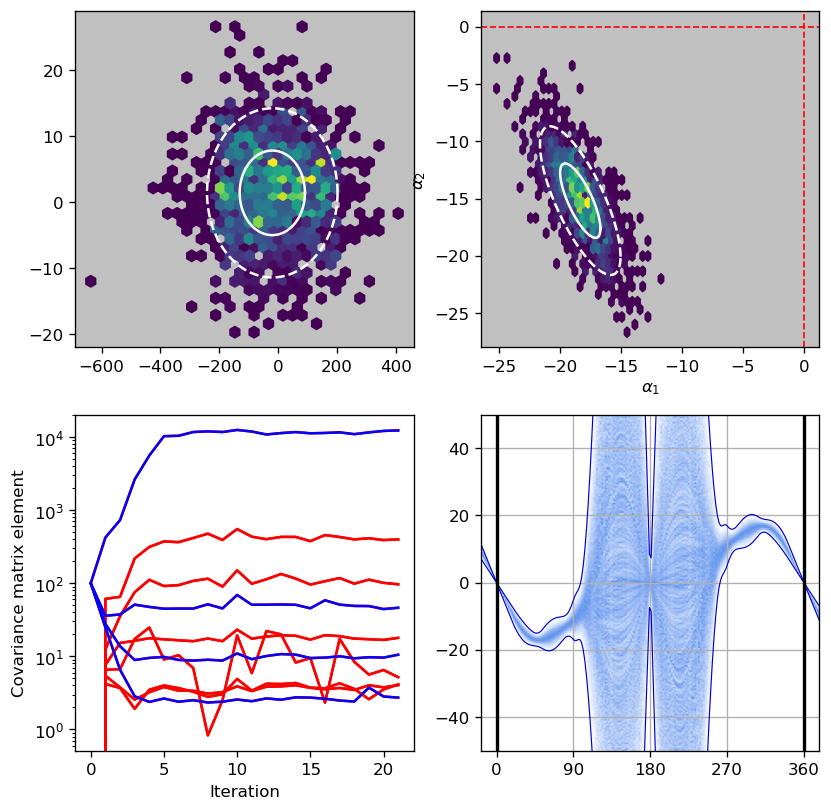

 42%|██████████████████████████████████▍                                               | 21/50 [06:38<08:44, 18.09s/it]

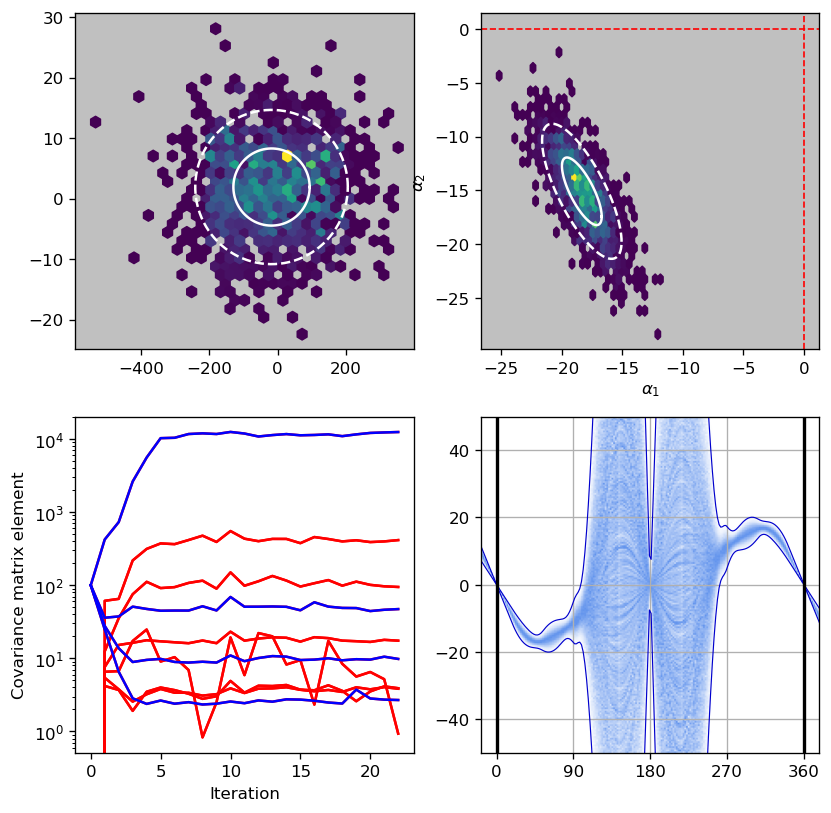

 44%|████████████████████████████████████                                              | 22/50 [06:56<08:24, 18.03s/it]

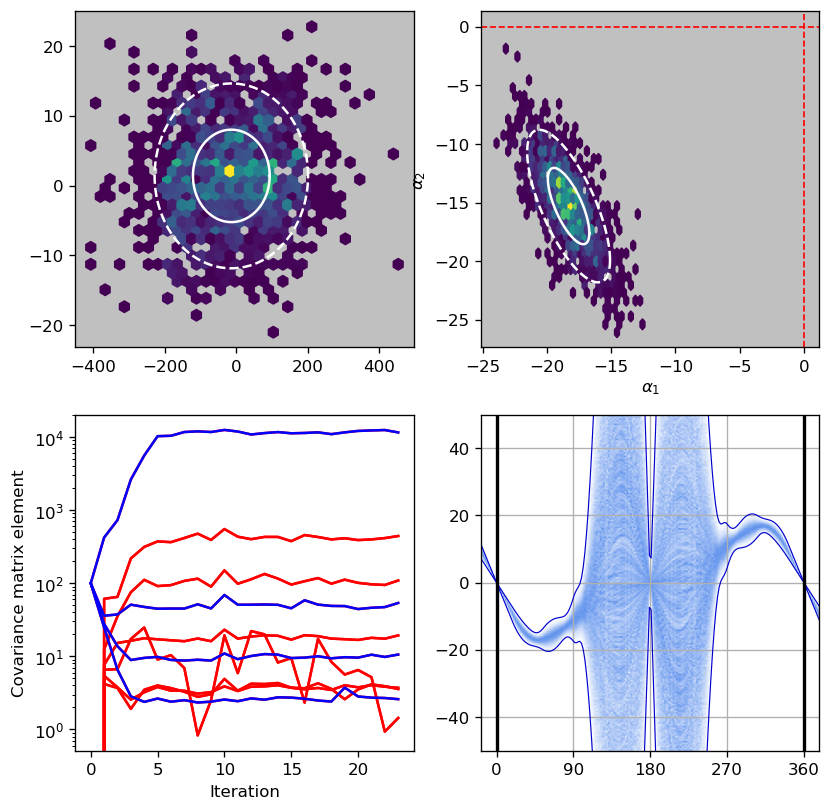

 46%|█████████████████████████████████████▋                                            | 23/50 [07:13<08:04, 17.93s/it]

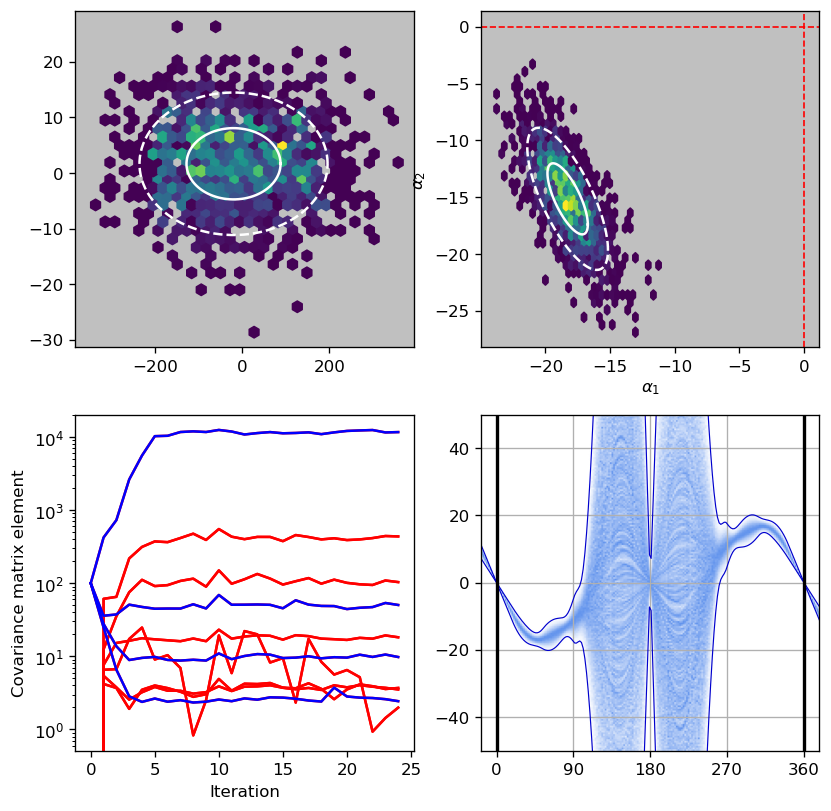

 48%|███████████████████████████████████████▎                                          | 24/50 [07:32<07:48, 18.01s/it]

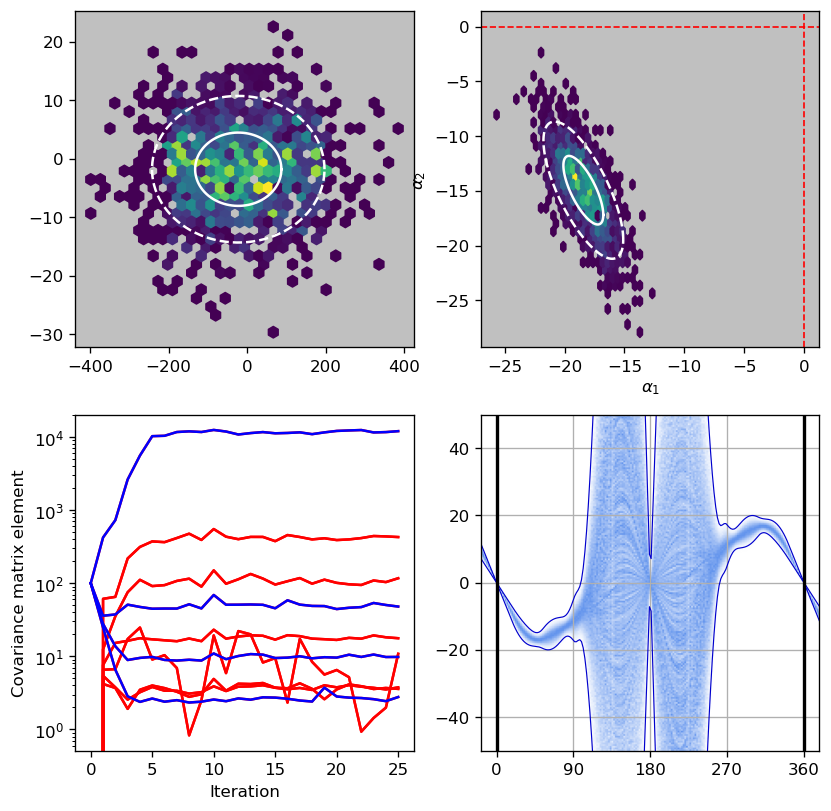

 50%|█████████████████████████████████████████                                         | 25/50 [07:50<07:30, 18.02s/it]

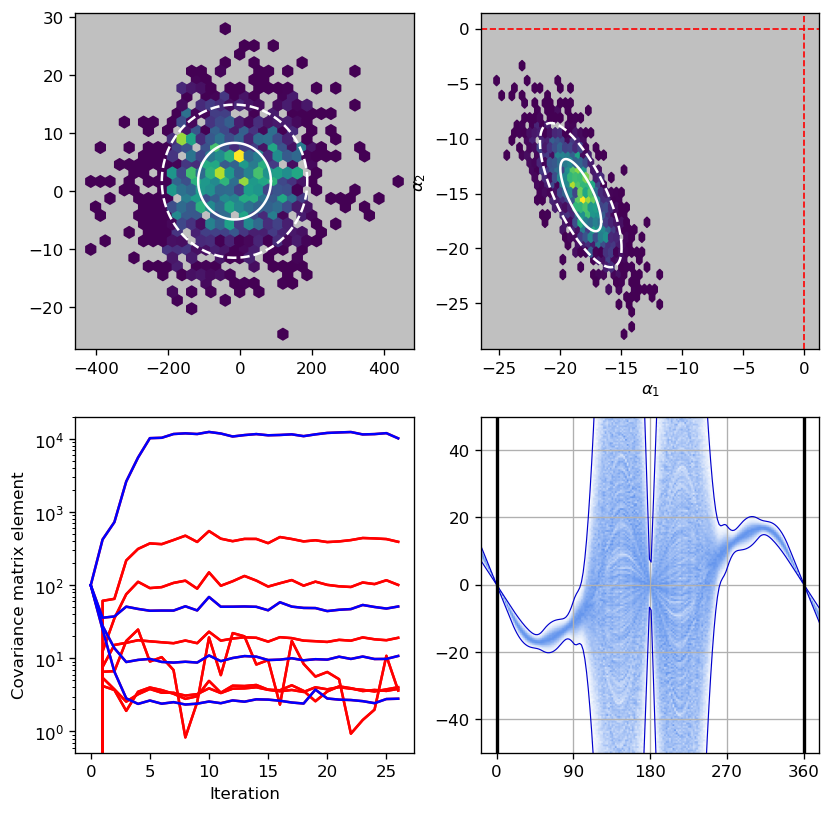

 52%|██████████████████████████████████████████▋                                       | 26/50 [08:08<07:12, 18.02s/it]

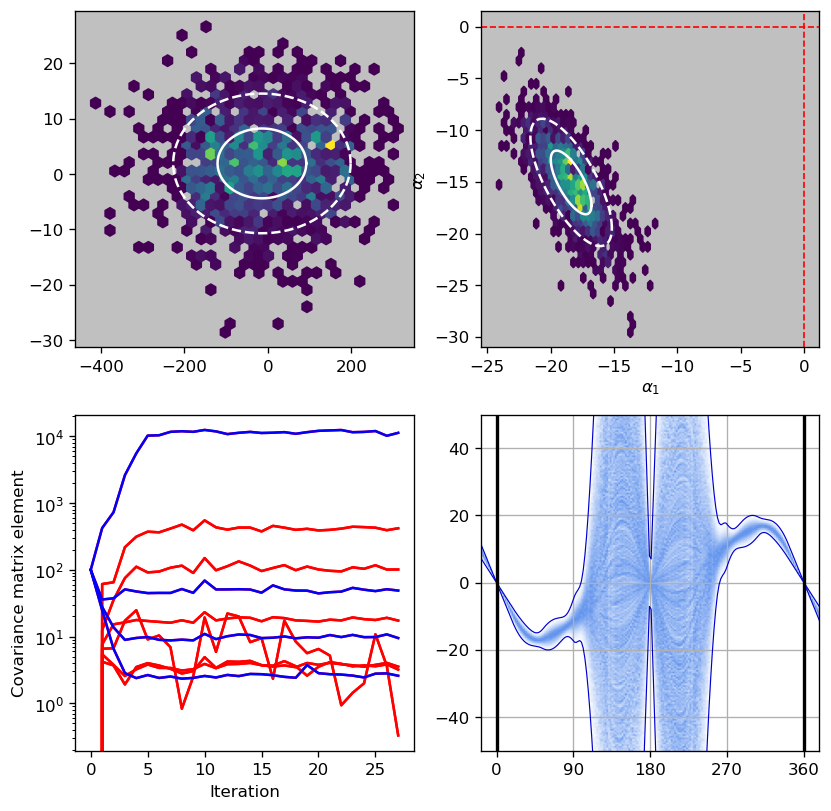

 54%|████████████████████████████████████████████▎                                     | 27/50 [08:26<06:55, 18.08s/it]

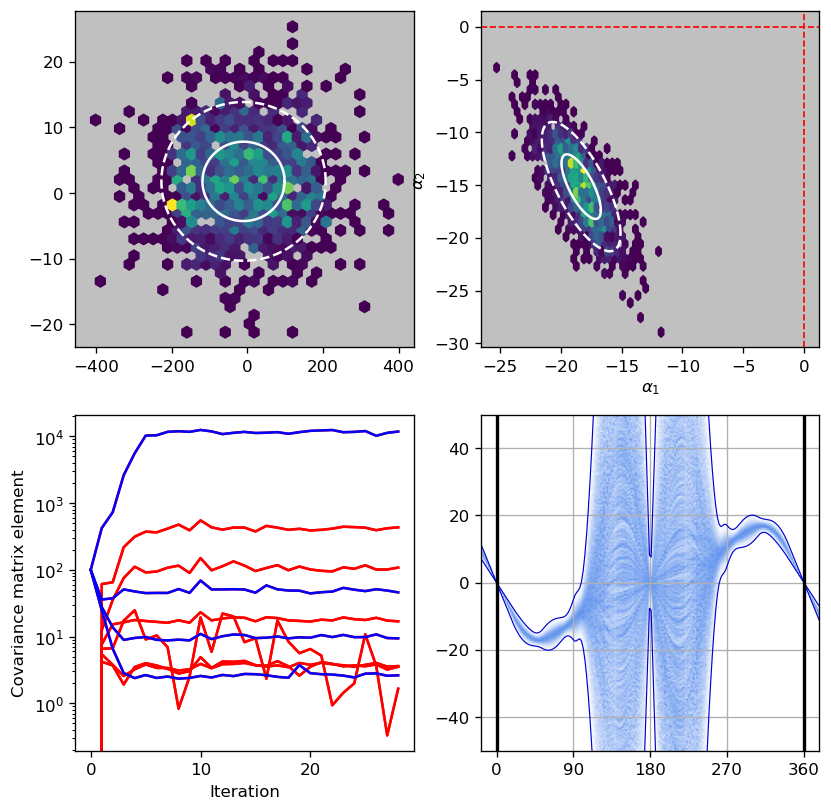

 56%|█████████████████████████████████████████████▉                                    | 28/50 [08:44<06:40, 18.19s/it]

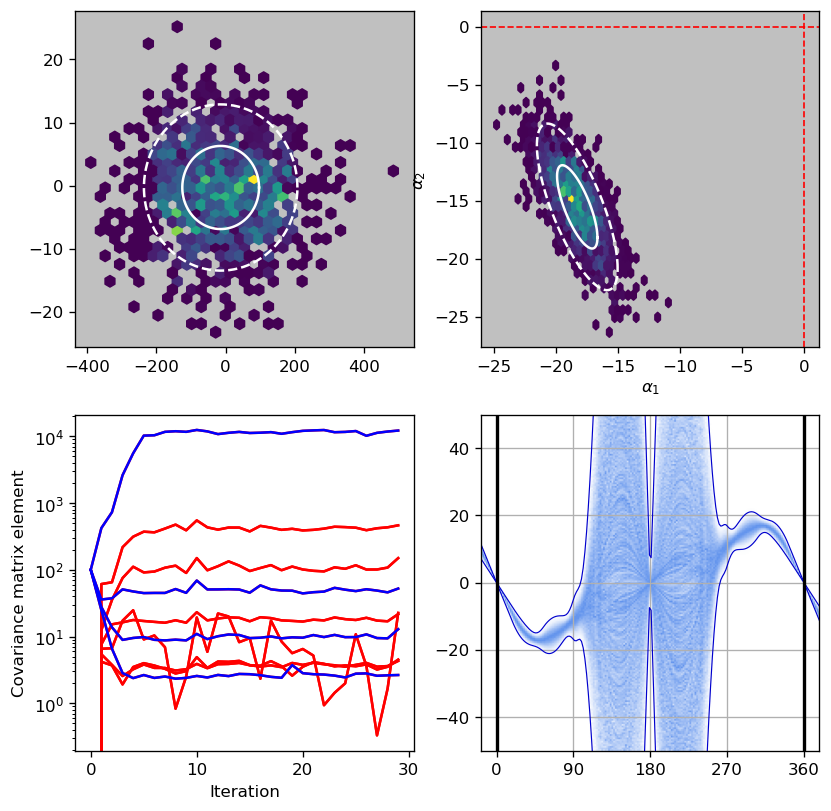

 58%|███████████████████████████████████████████████▌                                  | 29/50 [09:02<06:20, 18.10s/it]

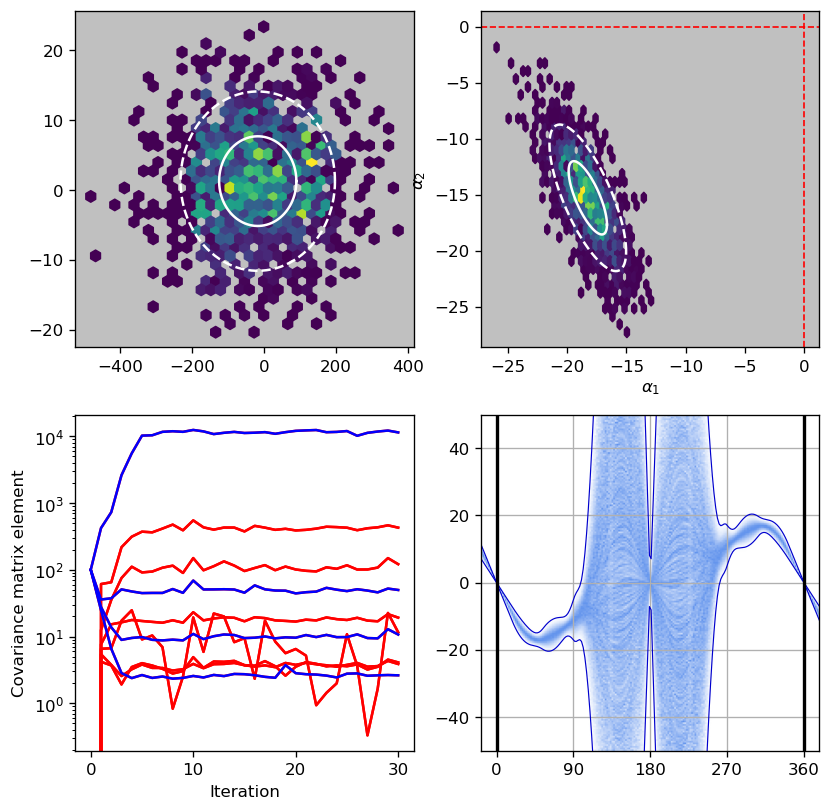

 60%|█████████████████████████████████████████████████▏                                | 30/50 [09:20<06:00, 18.04s/it]

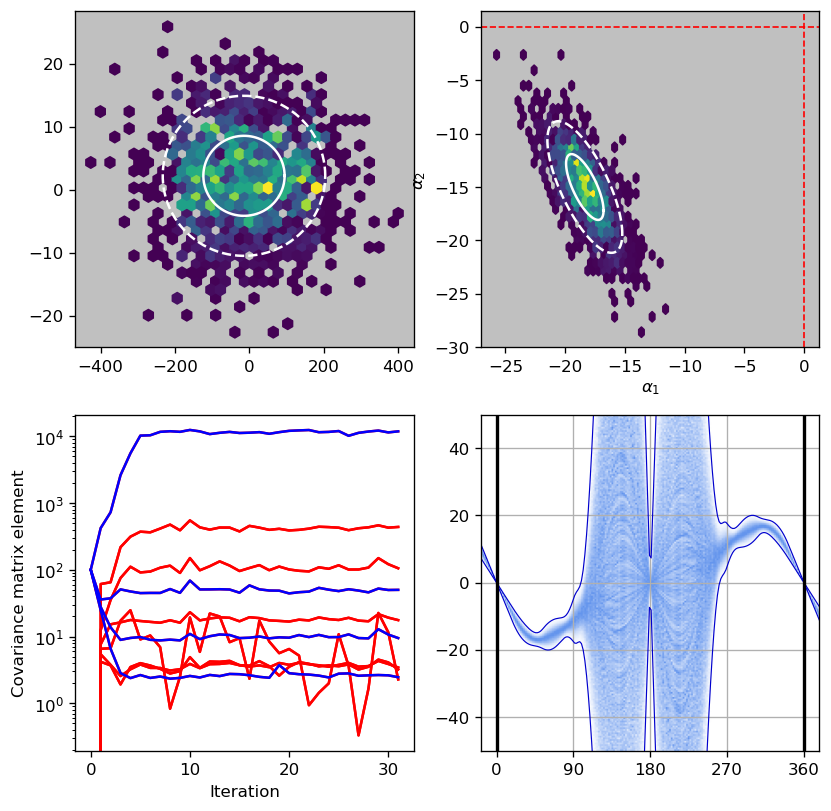

 62%|██████████████████████████████████████████████████▊                               | 31/50 [09:39<05:45, 18.17s/it]

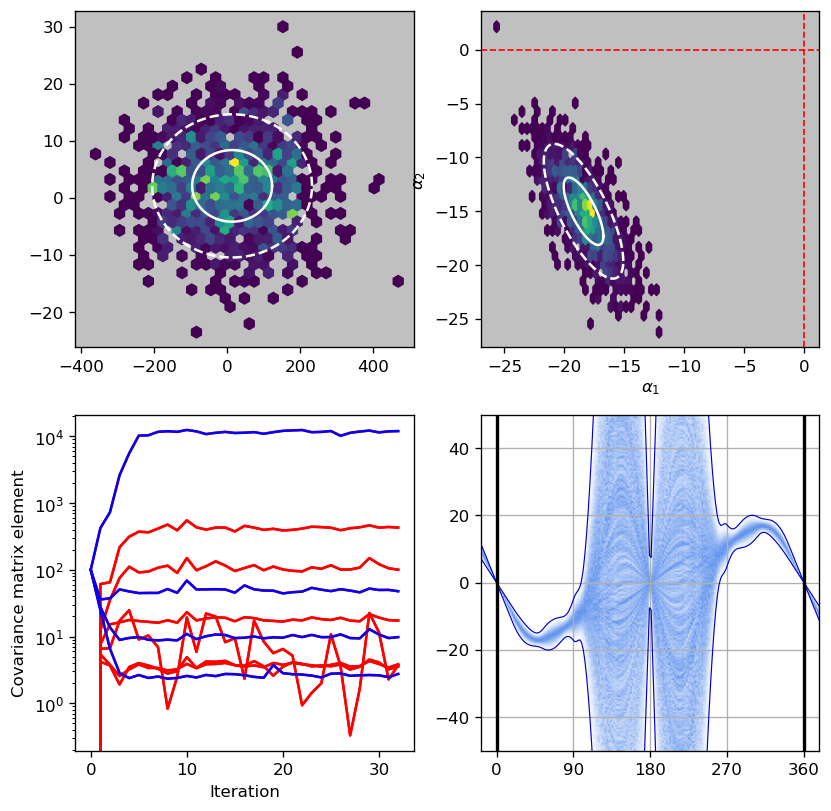

 64%|████████████████████████████████████████████████████▍                             | 32/50 [09:57<05:28, 18.26s/it]

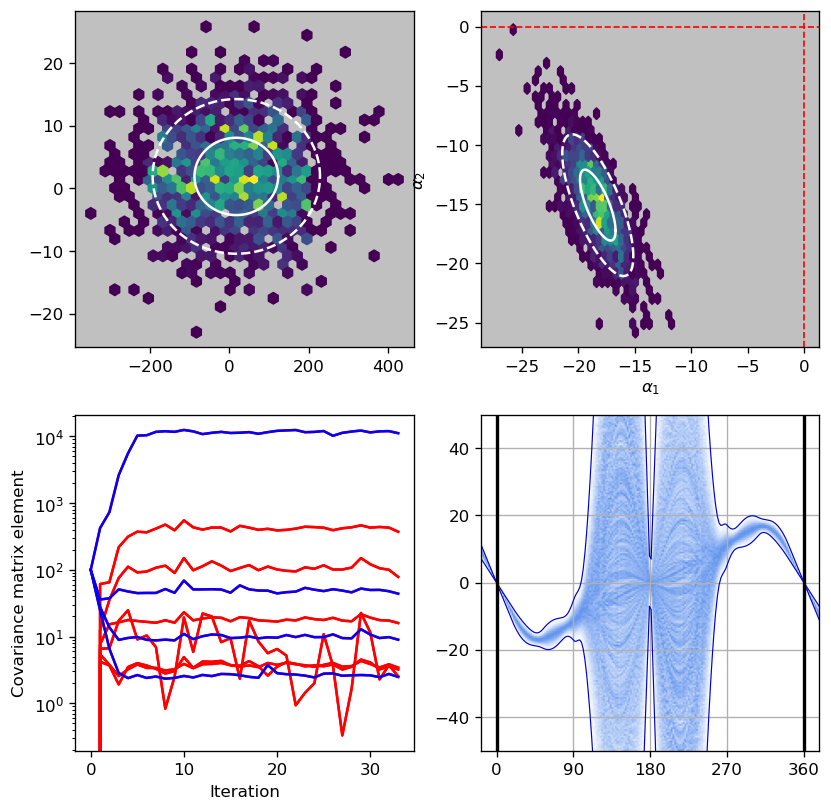

 66%|██████████████████████████████████████████████████████                            | 33/50 [10:15<05:08, 18.17s/it]

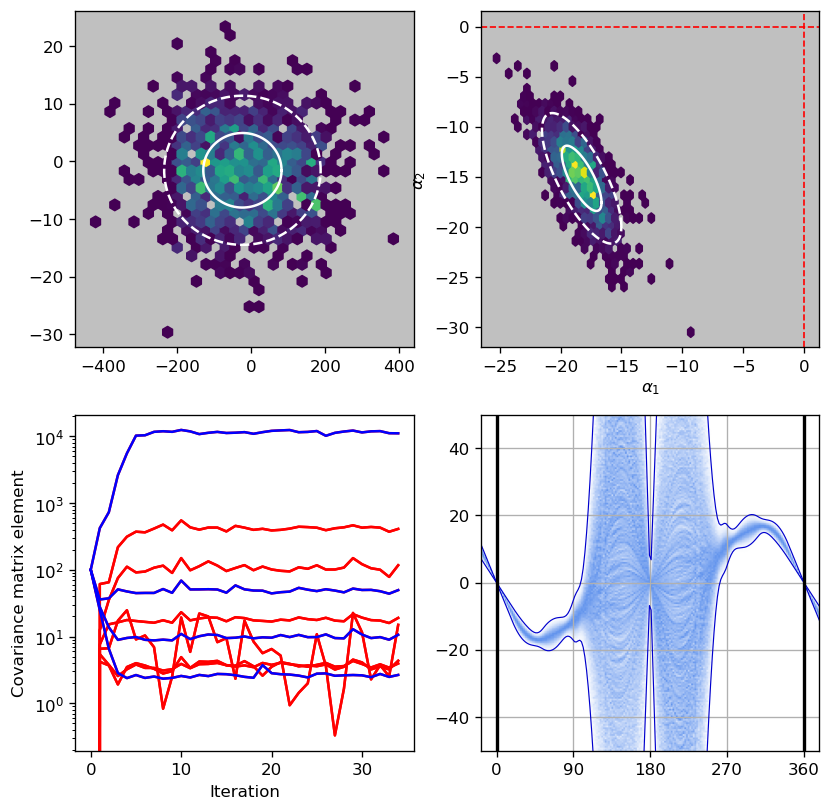

 68%|███████████████████████████████████████████████████████▊                          | 34/50 [10:33<04:50, 18.18s/it]

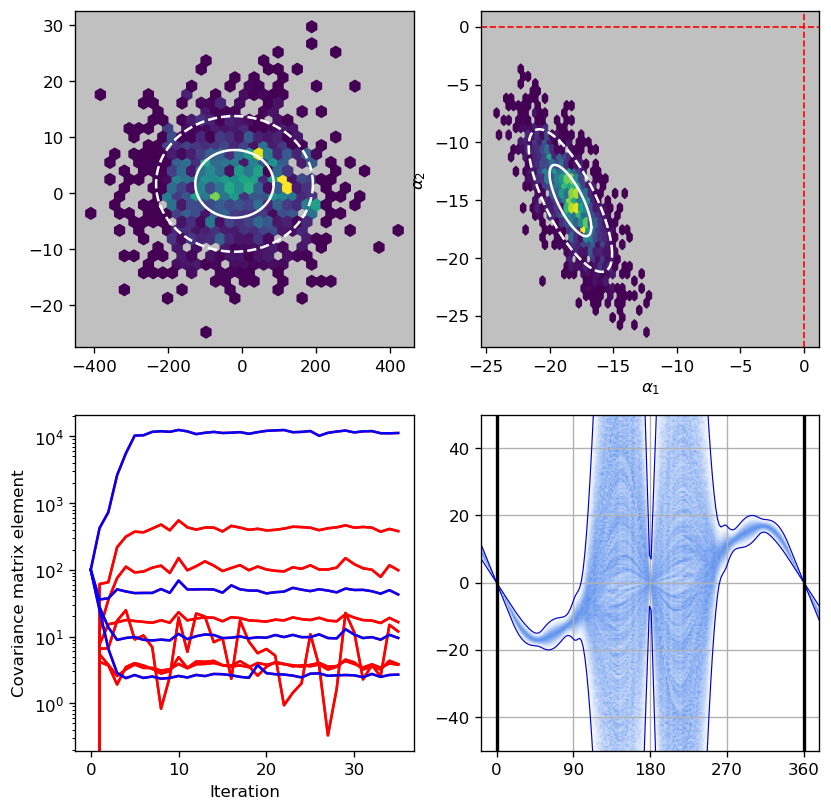

 70%|█████████████████████████████████████████████████████████▍                        | 35/50 [10:51<04:32, 18.14s/it]

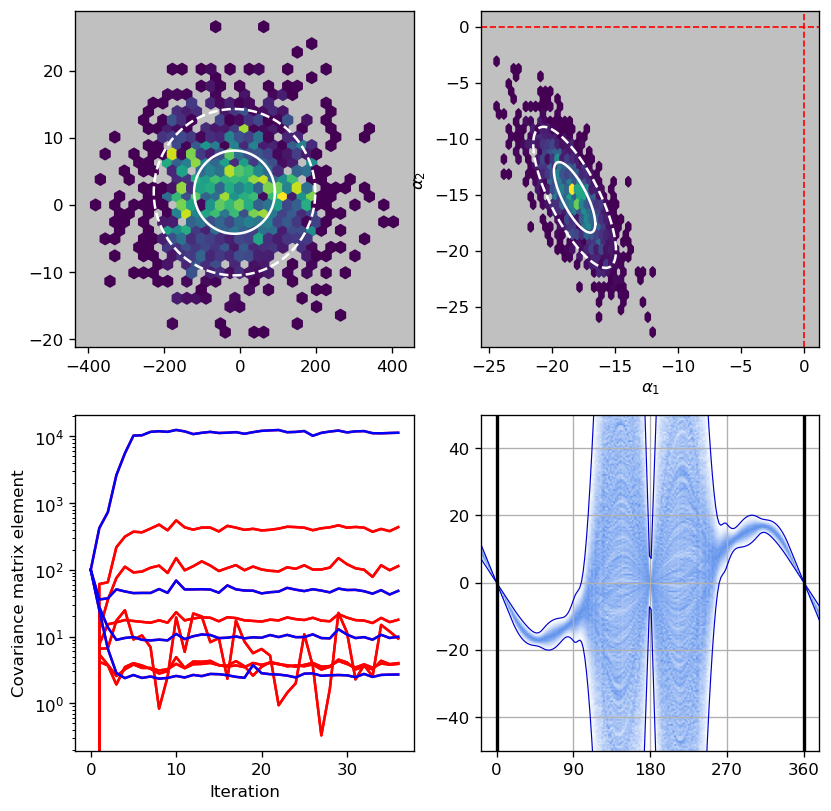

 72%|███████████████████████████████████████████████████████████                       | 36/50 [11:09<04:13, 18.14s/it]

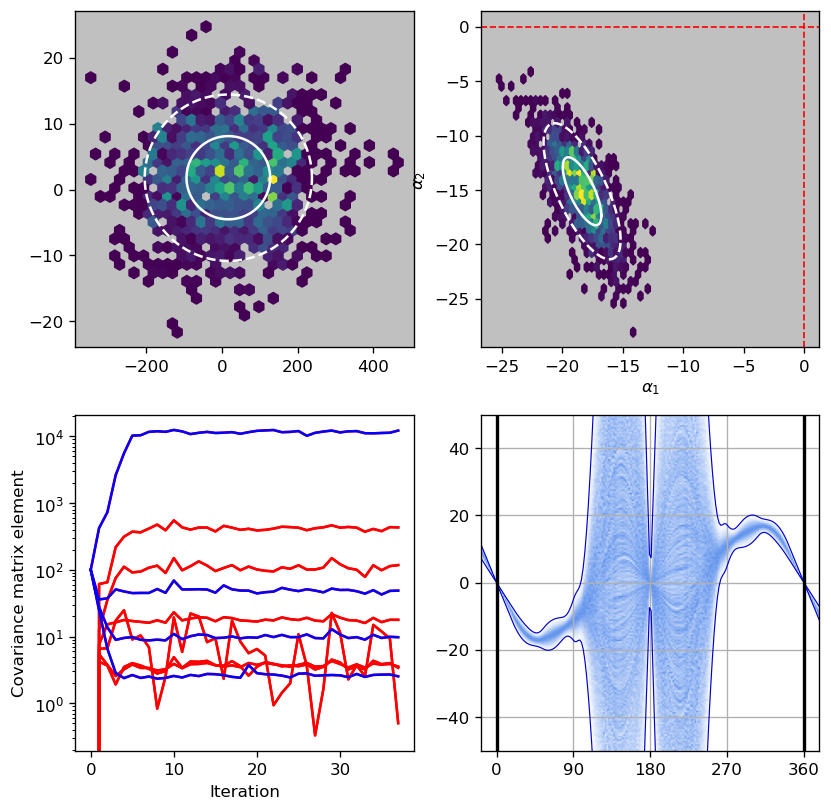

 74%|████████████████████████████████████████████████████████████▋                     | 37/50 [11:27<03:55, 18.10s/it]

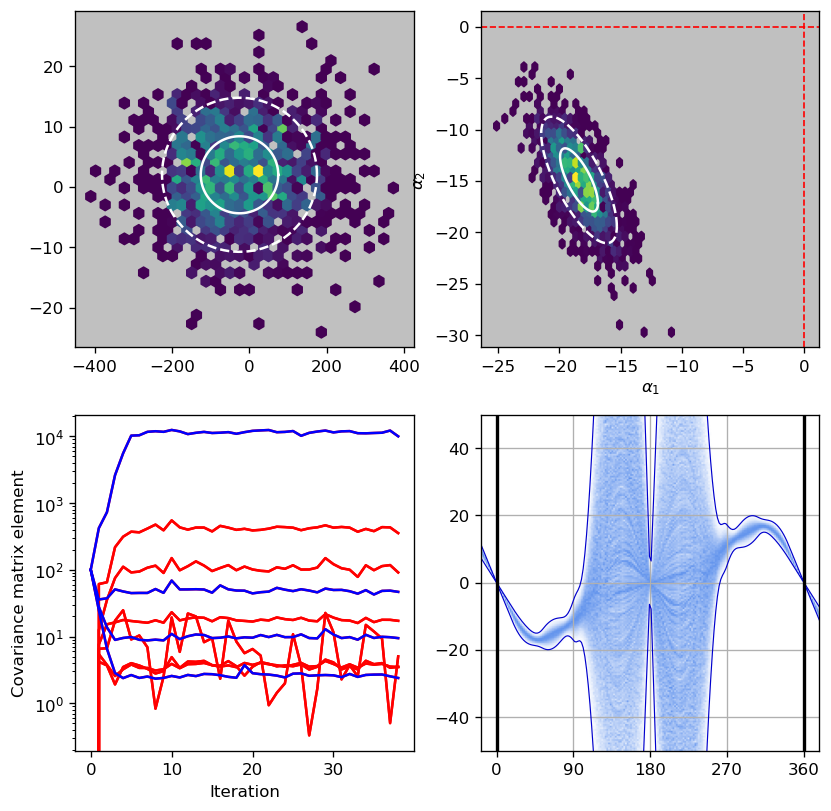

 76%|██████████████████████████████████████████████████████████████▎                   | 38/50 [11:45<03:36, 18.03s/it]

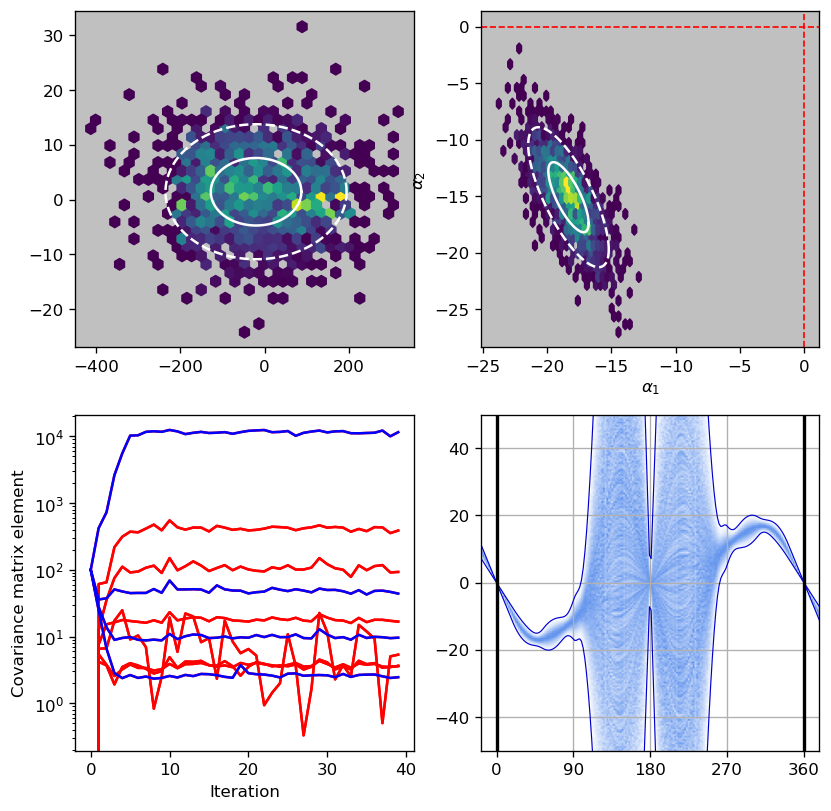

 78%|███████████████████████████████████████████████████████████████▉                  | 39/50 [12:04<03:20, 18.24s/it]

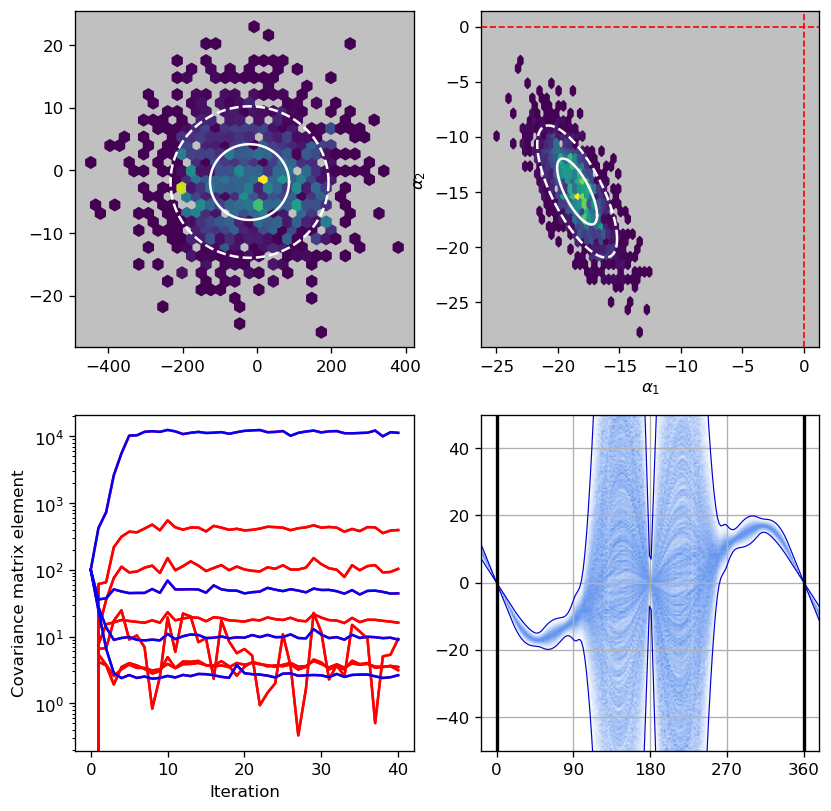

 80%|█████████████████████████████████████████████████████████████████▌                | 40/50 [12:22<03:02, 18.20s/it]

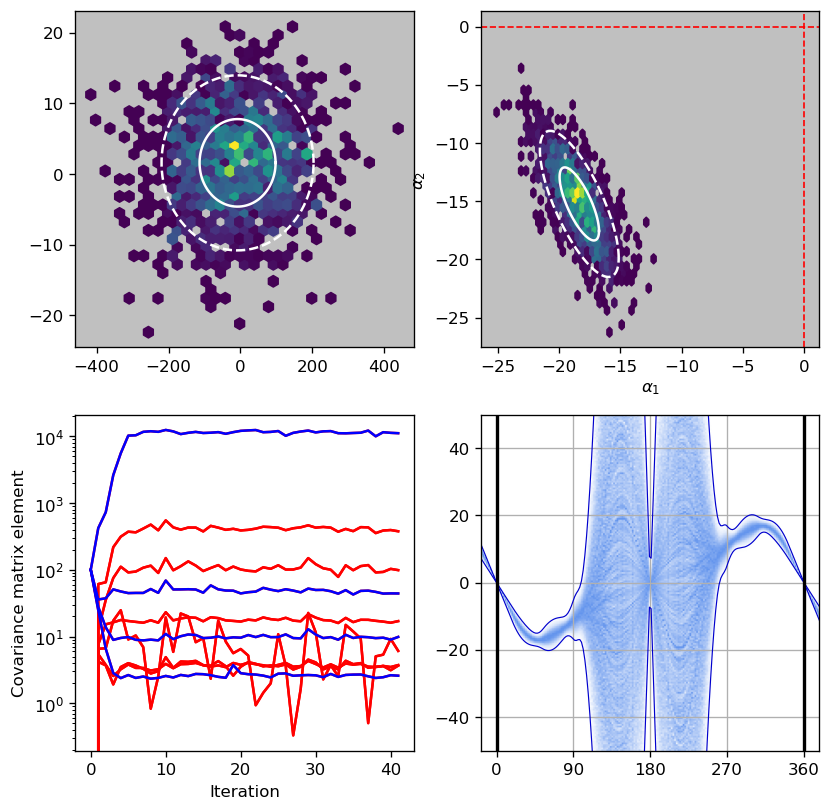

 82%|███████████████████████████████████████████████████████████████████▏              | 41/50 [12:41<02:44, 18.29s/it]

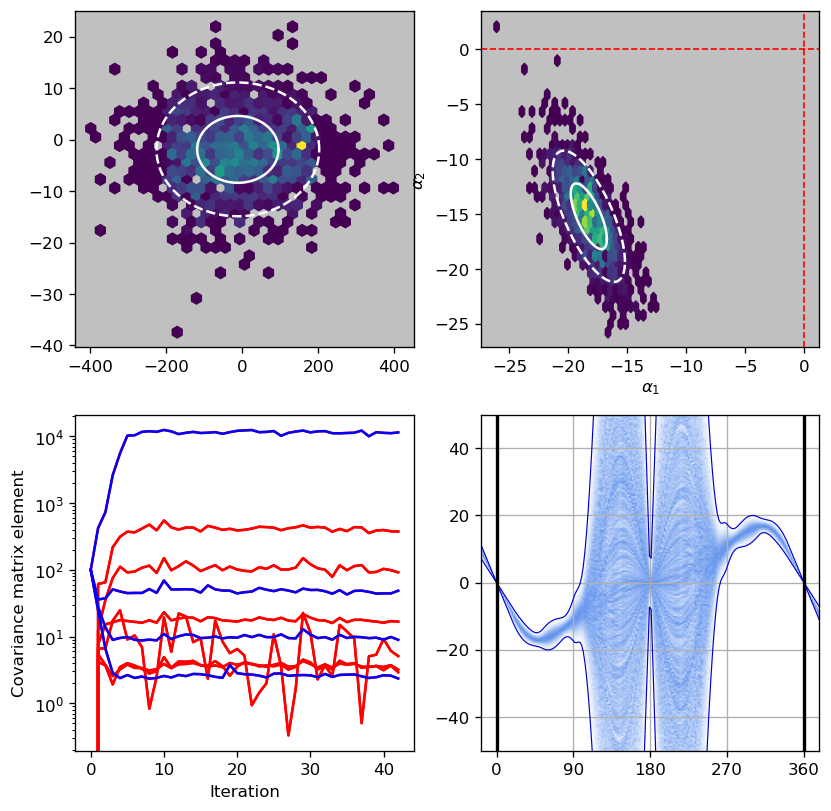

 84%|████████████████████████████████████████████████████████████████████▉             | 42/50 [12:59<02:27, 18.39s/it]

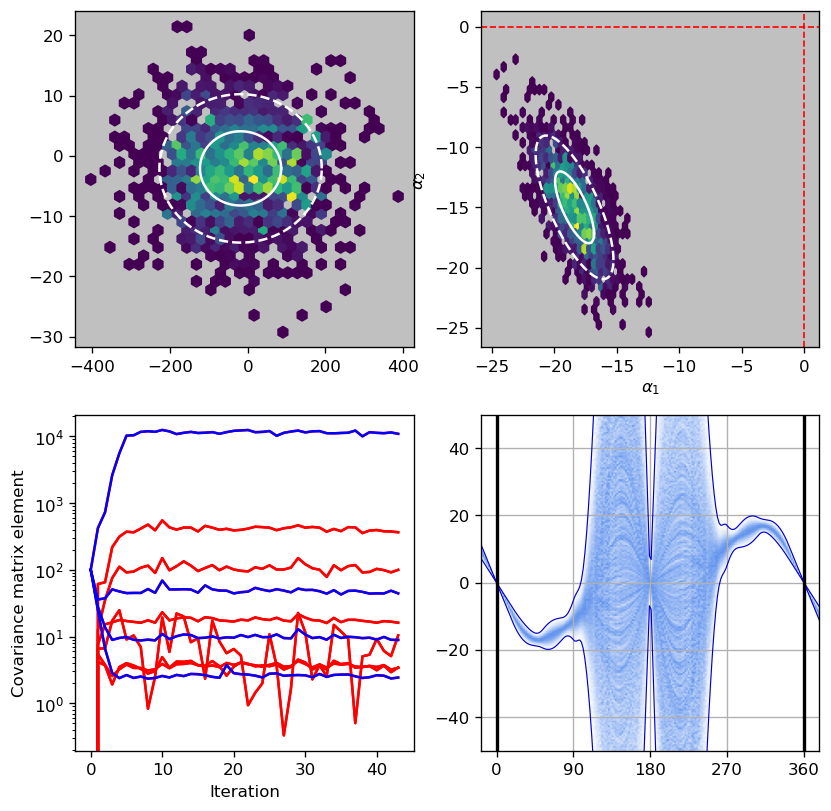

 86%|██████████████████████████████████████████████████████████████████████▌           | 43/50 [13:18<02:08, 18.37s/it]

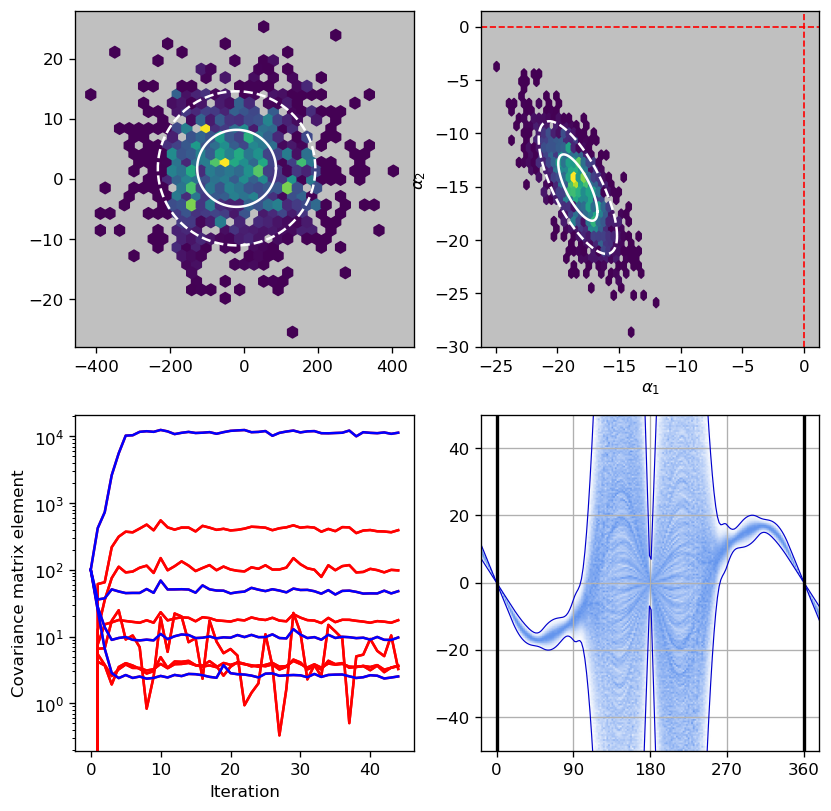

 88%|████████████████████████████████████████████████████████████████████████▏         | 44/50 [13:36<01:49, 18.29s/it]

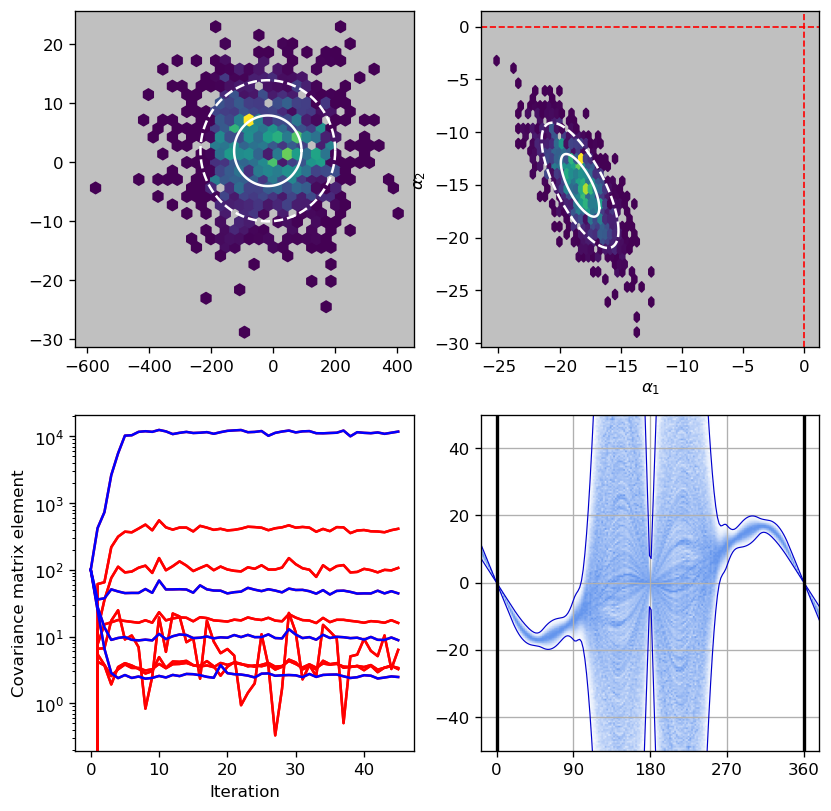

 90%|█████████████████████████████████████████████████████████████████████████▊        | 45/50 [13:54<01:31, 18.25s/it]

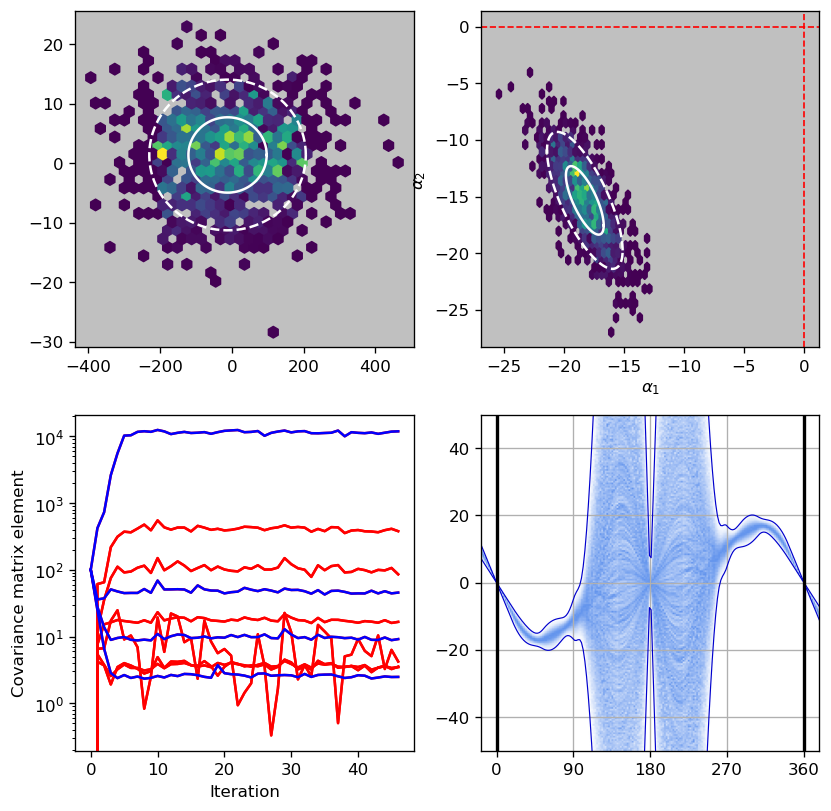

 92%|███████████████████████████████████████████████████████████████████████████▍      | 46/50 [14:12<01:12, 18.15s/it]

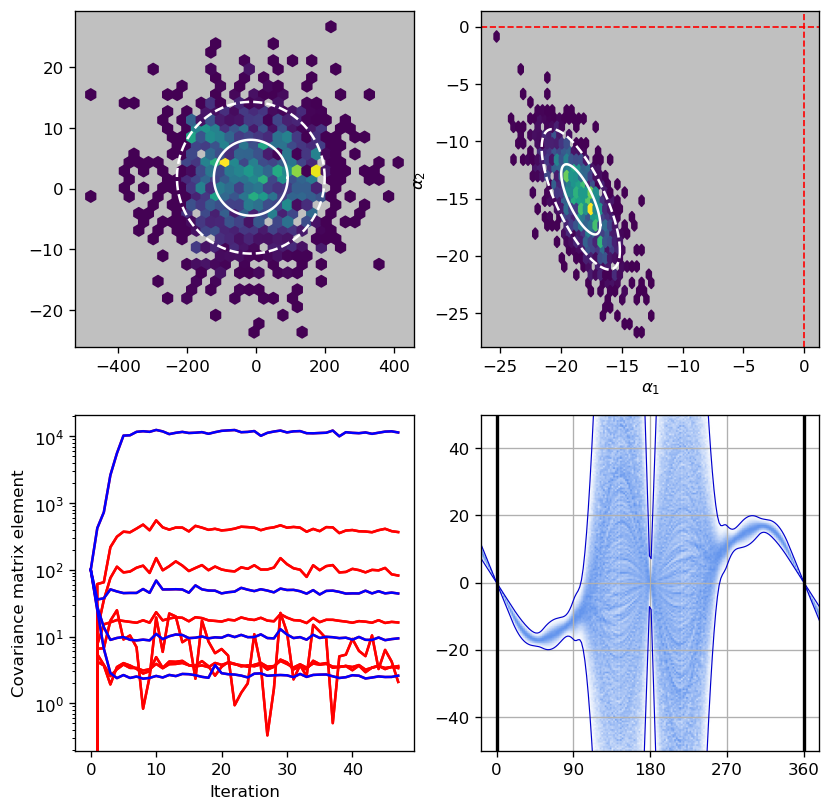

 94%|█████████████████████████████████████████████████████████████████████████████     | 47/50 [14:29<00:54, 18.01s/it]

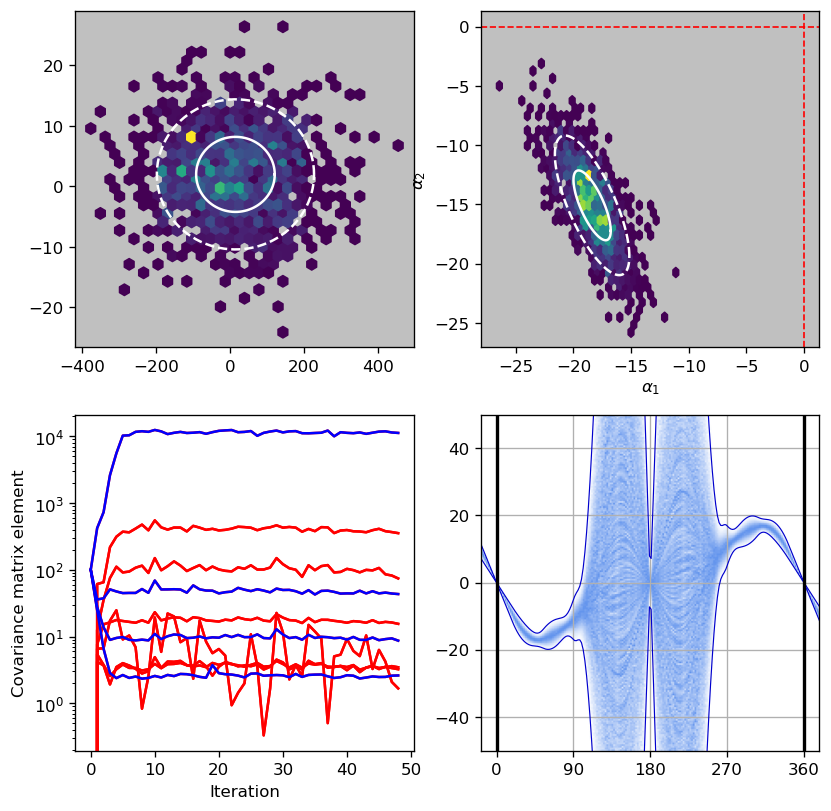

 96%|██████████████████████████████████████████████████████████████████████████████▋   | 48/50 [14:48<00:36, 18.08s/it]

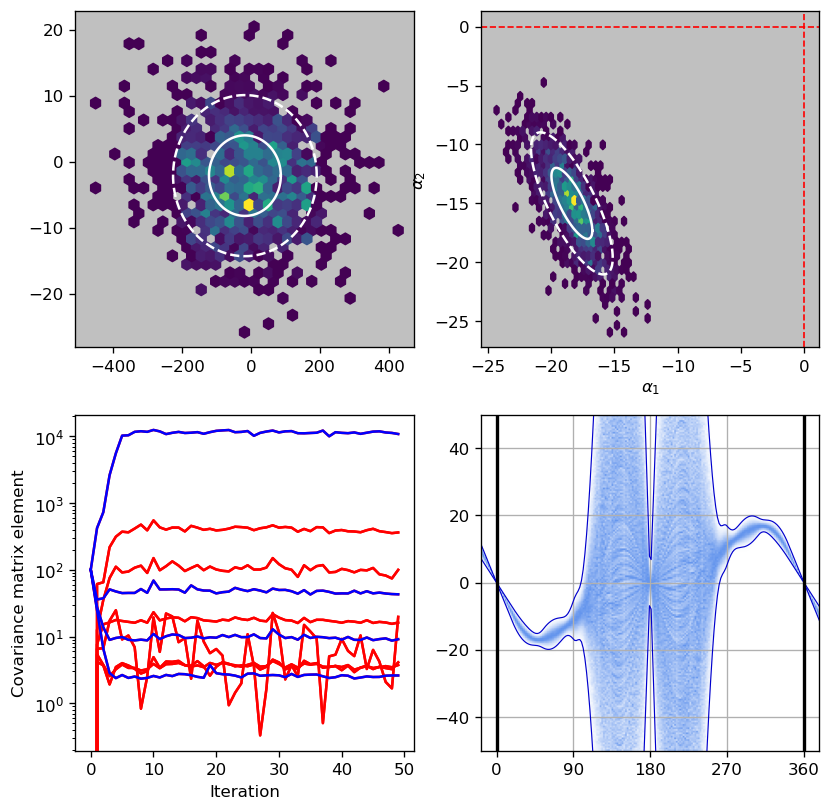

 98%|████████████████████████████████████████████████████████████████████████████████▎ | 49/50 [15:06<00:17, 17.99s/it]

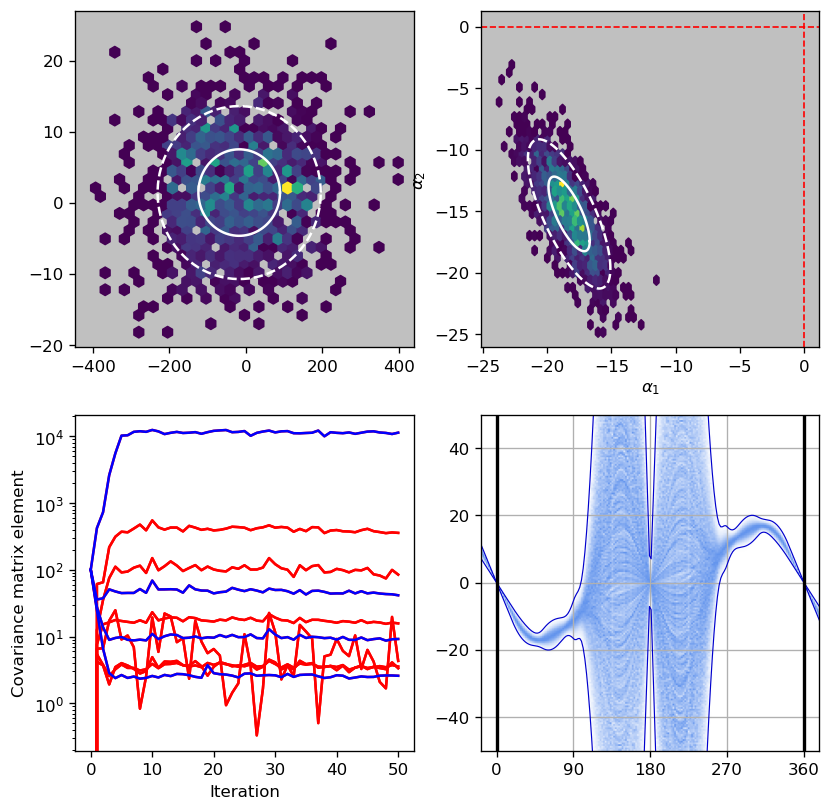

100%|██████████████████████████████████████████████████████████████████████████████████| 50/50 [15:23<00:00, 18.48s/it]


In [5]:
progression = range(50)
sample_count = 1024 // 1

for prog in tqdm(progression):

    ''' GENERATE NEW TEST SAMPLES '''

    distribution = multivariate_normal(mean=mean, cov=search_size*cov)
    coords = distribution.rvs(sample_count)
    likelihood = distribution.pdf(coords)

    ''' EVALUATE POSTERIOR AT TEST POINTS '''

    logl, _, _ = calc_logl_core(x_data, y_data, dt,
                                   PE, DT, DR, FORCE_STRENGTH,
                                   coords, torque_limit=max_angle,
                                   n_particles=100
                                   )
    logl = logl - np.max(logl)
    target_density = np.exp(logl)
    target_density = target_density / np.sum(target_density)

    # (Remnant of old testing code. More stable but incorrect.)
    ALL_COORDS = np.concatenate((ALL_COORDS, coords))
    ALL_TARGET_DENSITIES = np.concatenate((ALL_TARGET_DENSITIES, target_density))
    ALL_LIKELIHOODS = np.concatenate((ALL_LIKELIHOODS, likelihood))

    # (Delete old data, otherwise the fit isn't correct -> Mitigating above issue.)
    ALL_COORDS = coords
    ALL_TARGET_DENSITIES = target_density
    ALL_LIKELIHOODS = likelihood

    ''' CALULATE NEW MEAN AND COVARIANCE'''
    mean_old = mean
    cov_old = cov
    mean = np.average(ALL_COORDS, axis=0, weights=ALL_TARGET_DENSITIES/ALL_LIKELIHOODS)
    cov = np.cov(ALL_COORDS.T, aweights=ALL_TARGET_DENSITIES/ALL_LIKELIHOODS)

    # (Stabilize the fit by mixing the old and new parameters)
    mixing_ratio = 0.8
    mean = mixing_ratio * mean + (1 - mixing_ratio) * mean_old
    cov = mixing_ratio * cov + (1 - mixing_ratio) * cov_old

    ''' STORE PROGRESS '''

    COVS.append(cov.copy())
    MEANS.append(mean.copy())

    eivals, eivecs = np.linalg.eig(cov)
    idx = np.argsort(np.abs(eivals))[::-1]
    eivals = eivals[idx]
    eivecs = eivecs[:, idx]




    plt.figure(dpi=120, figsize=(8, 8))
    ''' PLOT ROTATED PARAMETERS '''

    def rotate(vec):
        return np.dot(vec, eivecs)
    
    def rotate_mat(mat):
        return np.dot(np.dot(eivecs.T, mat), eivecs)
    
    plt.subplot(2, 2, 1)
    plt.gca().set_facecolor('silver')
    #chan = np.exp(ALL_TARGET_DENSITIES/10)
    chan = ALL_TARGET_DENSITIES
    plt.hexbin(rotate(ALL_COORDS)[:, d0], rotate(ALL_COORDS)[:, d1], C=chan, gridsize=32)
    plot_cov_ellipse(rotate(mean), rotate_mat(cov), color='w')

    ''' PLOT ORIGINAL PARAMETERS '''

    plt.subplot(2, 2, 2)
    plt.gca().set_facecolor('silver')
    #chan = np.exp(ALL_TARGET_DENSITIES/10)
    chan = ALL_TARGET_DENSITIES
    plt.hexbin((ALL_COORDS)[:, d0], (ALL_COORDS)[:, d1], C=chan, gridsize=32, reduce_C_function=np.max)
    plt.axvline(centers[0], color='r', linestyle='--', lw=1)
    plt.axhline(centers[1], color='r', linestyle='--', lw=1)
    plot_cov_ellipse(mean, cov, color='w')

    plt.xlabel(r'$\alpha_1$')
    plt.ylabel(r'$\alpha_2$')

    ''' PLOT CONVERGENCE '''

    plt.subplot(2, 2, 3)

    COVS_flat = [cov_.copy() for cov_ in COVS]
    for cov_ in COVS_flat:
        np.fill_diagonal(cov_, np.nan)
    COVS_flat = [cov_.flatten() for cov_ in COVS]

    COVS_flat = np.stack(COVS_flat, axis=0)
    plt.semilogy(np.abs(COVS_flat), 'red', label='Covariances')

    COVS_flat = [np.diagonal(cov) for cov in COVS]
    COVS_flat = np.stack(COVS_flat, axis=0)
    plt.semilogy(np.abs(COVS_flat), 'blue', label='Diagonals')
    plt.xlabel("Iteration")
    plt.ylabel("Covariance matrix element")

    ''' PLOT POSTERIOR TORQUE '''

    plt.subplot(2, 2, 4)
    plot_torques(MEANS, COVS, n_knots=ndims)

    plt.savefig(f"img/proposal_convergence{count}.png", dpi=600)
    plt.show()
    count += 1

In [9]:
np.save("mean.npy", MEANS[-1])
np.save("cov.npy", COVS[-1])

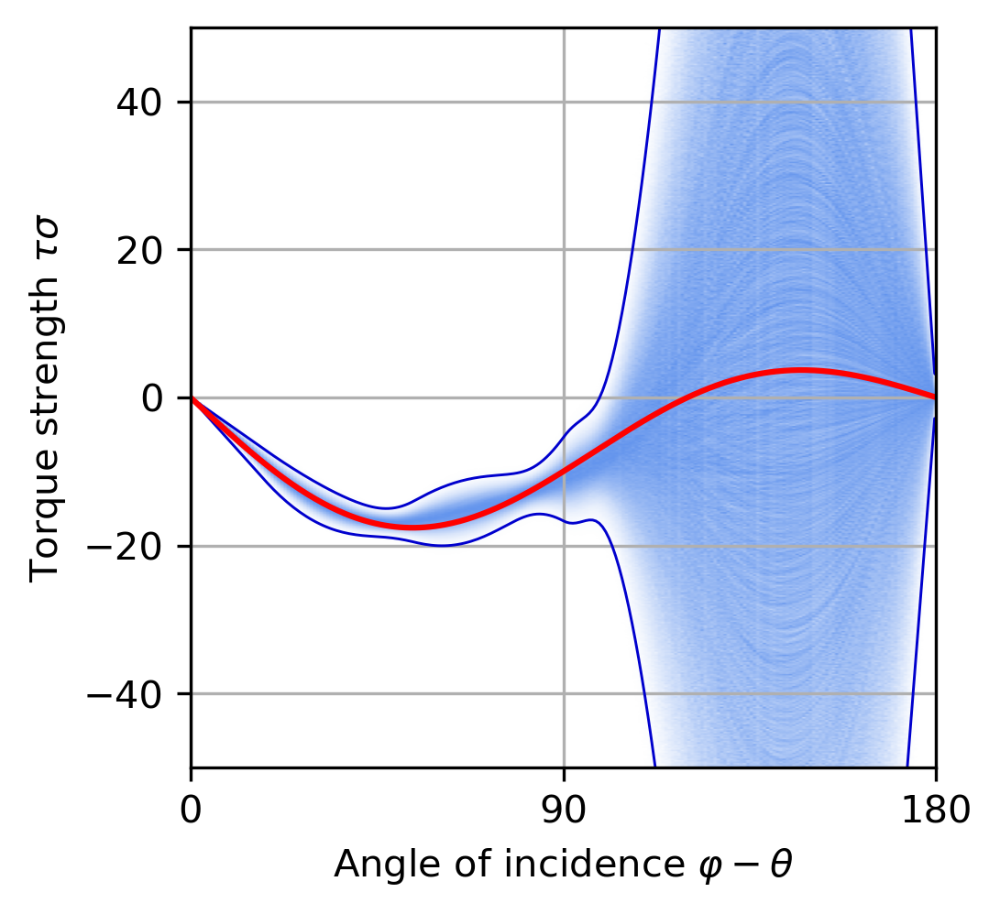

In [10]:
mean = np.load("mean.npy")
cov = np.load("cov.npy")
plt.figure(figsize=(3.5, 3.5), dpi=300)
sel = -2
plot_torques([mean], [cov], n_knots=ndims, n_samples=100000, n_phis=500, n_examples=0, use_Bsplines=True, plot_edges=False)
plt.xlim([0, 180])
phi_ = np.linspace(0, np.pi, 300)
torque_ = TORQUE(phi_, ALPHAS)
plt.plot(phi_*180/np.pi, torque_, 'r')
plt.xlabel(r"Angle of incidence $\varphi-\theta$")
plt.ylabel(r"Torque strength $\tau\sigma$")
plt.savefig("inference_abp_result.png", dpi=300)

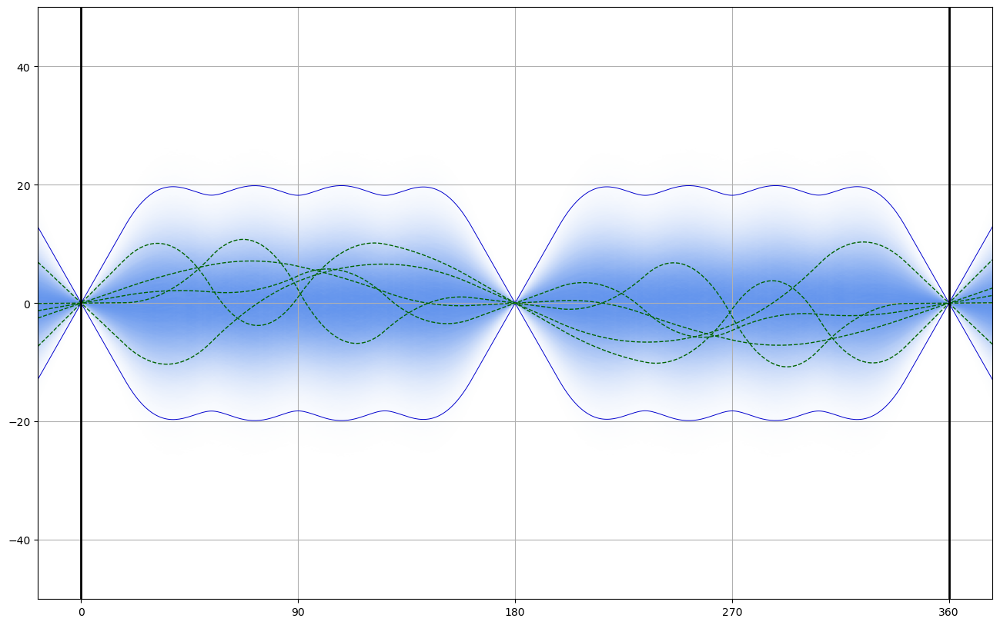

In [7]:
plt.figure(figsize=(16, 10))
sel = 0
plot_torques(MEANS[sel:sel+1], COVS[sel:sel+1], n_knots=ndims, n_samples=1000000, n_phis=500, n_examples=5)

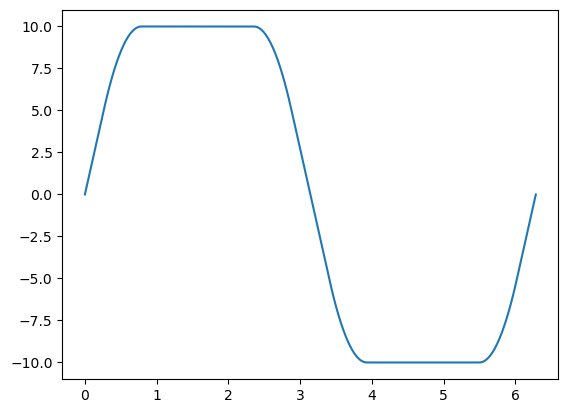

In [8]:
phi = np.linspace(0, 2*np.pi, 200)
params = np.array([10]*5)
tq = TORQUE_FILTER(phi, params)
plt.plot(phi, tq)